# Zimbabwe maize yield atlas

Where do we have yield measurements, how did rainfall vary across the sampled regions, and how closely do satellite-based estimates track the crop cuts? Start with the **Zimbabwe maps**, then explore **yield distributions**, **satellite observations and model estimates**, and **weather associations**. The **repository figure gallery** at the end brings together visuals from Zimbabwe, Kenya and Malawi and links each one to its source.

Jin et al. mapped maize in Kenya and Tanzania. Their geographic panels (Fig. 5), yield distributions (Fig. 6a), crop-cut validation (Fig. 4) and environmental correlations (Fig. 7a) inspired the designs here. Zimbabwe's crop cuts have point locations. Colored yield cells summarize the fields actually sampled within them. The NASA maps have coarser spatial support, shown at the native weather-grid resolution. [Read the paper](https://doi.org/10.1016/j.rse.2019.04.016).

[Zimbabwe maps](#zimbabwe-maps) · [Yield distributions](#yield-distributions-across-harvests) · [Satellite and model figures](#satellite-observations-and-model-estimates) · [Weather associations](#how-regional-weather-and-measured-yield-vary-together) · [Existing figure gallery](#repository-figure-gallery)

**Run the atlas.** Open this notebook in a Git checkout, select the project's Python environment and run the cells in order. The figures below also have saved outputs for reading on GitHub. New PNGs and the source index are in the [atlas output folder](../results/visual_atlas/). [Environment requirements](../requirements.txt).

In [1]:
from pathlib import Path
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / "configs" / "team_database_v2.json").is_file())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
OUT = ROOT / "results" / "visual_atlas"
OUT.mkdir(parents=True, exist_ok=True)
weather_dir = ROOT / "data" / "processed" / "zimbabwe_weather_v2"
fields = pd.read_parquet(weather_dir / "harmonized_labels_weather.parquet")
assert fields.obs_id.is_unique and fields.country_iso3.eq("ZWE").all()
assert np.isfinite(fields.yield_t_ha).all()

def show_file(path):
    display(Image(filename=str(path), width=1000))

def export_figure(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    show_file(path)

Matplotlib is building the font cache; this may take a moment.


## Zimbabwe maps

The yield maps use the screened crop-cut catalog. That includes all 169 Lacuna 2022 records as ground observations. Their archived satellite coverage is one or two December–June months per field, below the four months required for the aggregation experiments. Weather comes from the project’s archived NASA POWER data. Map coverage, the number of fields contributing to a colored cell, and its physical size determine how each panel can be read. [Yield and weather methods](../docs/zimbabwe/METHODS.md).

### Crop-cut yields by harvest year

Within each 25 km × 25 km equal-area cell, we average the crop cuts when at least five sampled fields fall inside the national outline. Dark gray marks cells with one to four records. Pale land shows areas with no mapped records. The 2024 panel includes the source's recorded zeros. Fifty-two of its screened locations fall outside the generalized outline and appear only in non-geographic catalog summaries. [Boundary and city attribution](../results/visual_atlas/sources/natural_earth_provenance.json).

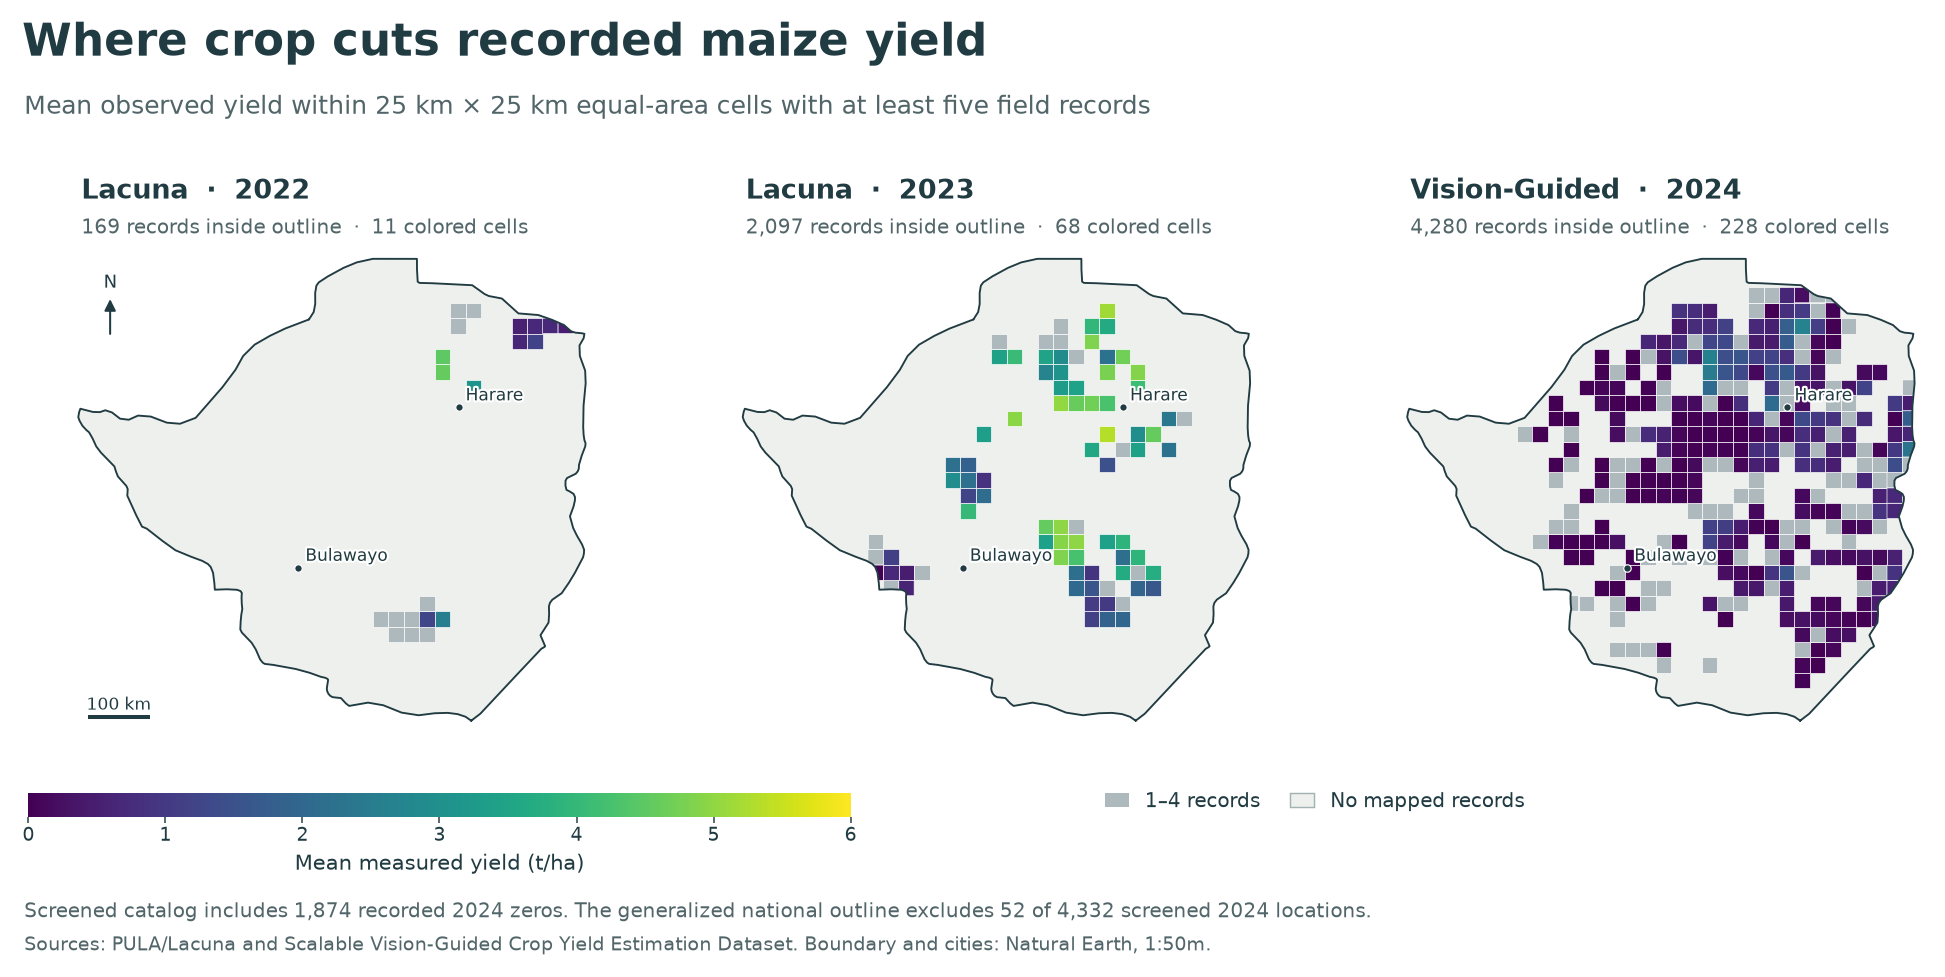

,screened_or_scored_records,inside_outline,outside_outline,colored_cells,records_in_colored_cells,sparse_cells,records_in_sparse_cells
harvest year,,,,,,,
2022,169,169,0,11,147,10,22
2023,2097,2097,0,68,2057,15,40
2024,4332,4280,52,228,4056,97,224


In [2]:
import json
from scripts.paper.atlas_maps import build_maps

map_figures = build_maps(ROOT, OUT)
for figure in map_figures.values():
    plt.close(figure)
map_data = json.loads((OUT / "map_data_summary.json").read_text())
show_file(OUT / "yield_map.png")
display(pd.DataFrame.from_dict(map_data["observed_yield"], orient="index").rename_axis("harvest year"))

### Rainfall and temperature

January–March conditions are shown against each cell's 1991–2020 reference. A rain value of 60% means the cell received 60% of its normal seasonal total. A temperature anomaly of +1 °C means the season averaged one degree above normal. The same archived POWER cells appear in each year wherever their footprints intersect Zimbabwe. [Weather source and archived grids](../data/processed/zimbabwe_weather_v2/README.md).

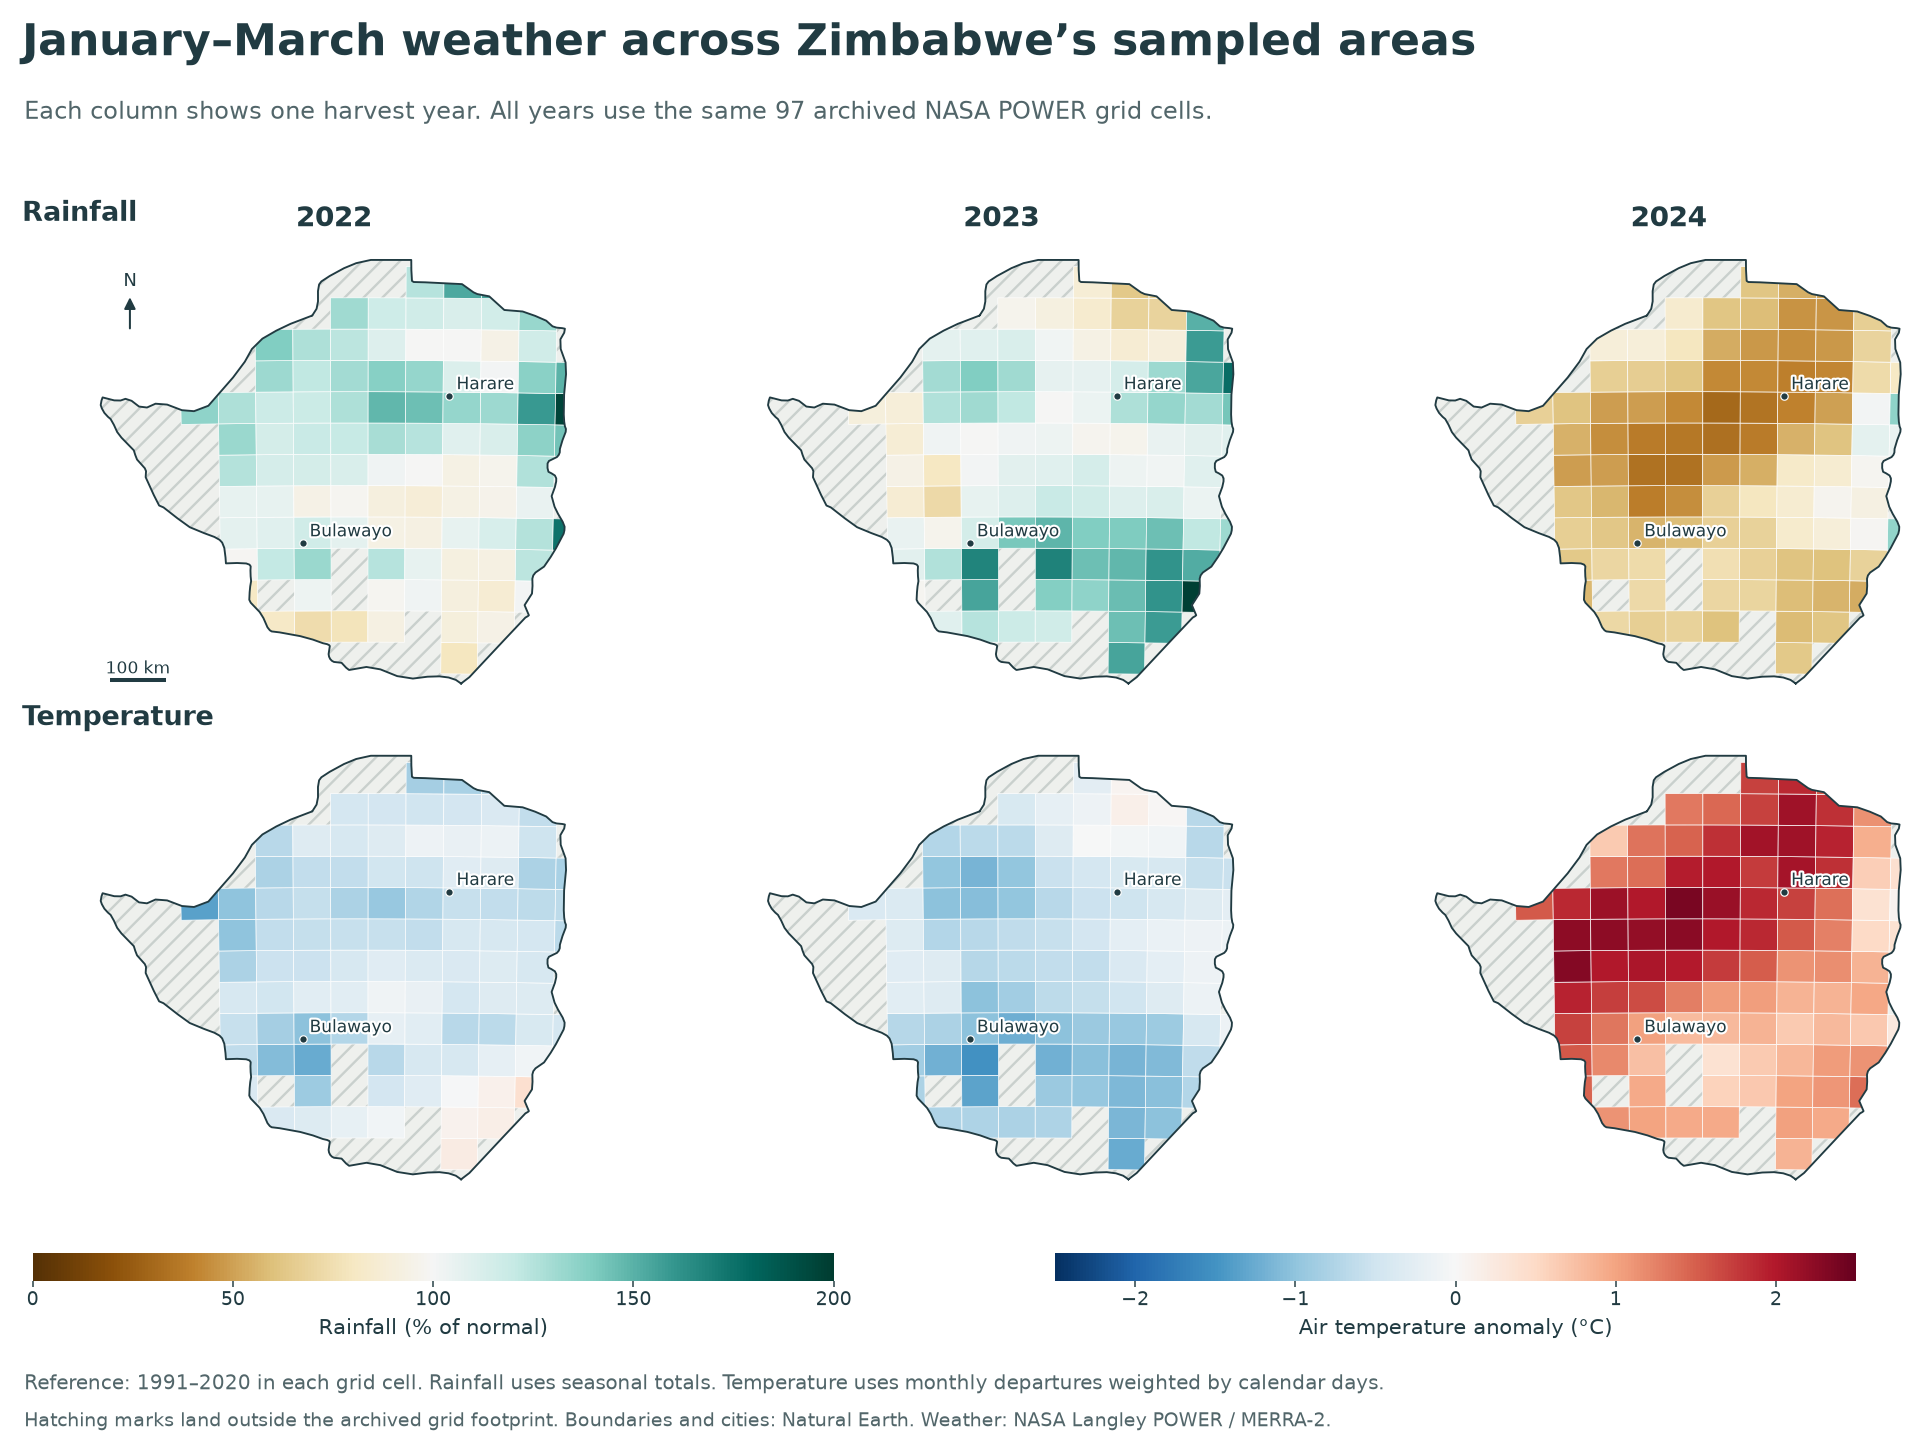

,Median rainfall (% of normal),Median temperature anomaly (°C)
Harvest year,,
2022,113.68,-0.46
2023,110.70,-0.64
2024,62.16,1.34


In [3]:
show_file(OUT / "weather_map.png")
weather_summary = pd.DataFrame({
    int(year): {"Median rainfall (% of normal)": v["rain_pct"]["median"],
                "Median temperature anomaly (°C)": v["temp_anomaly"]["median"]}
    for year, v in map_data["weather"]["years"].items()
}).T.rename_axis("Harvest year")
display(weather_summary.round(2))

### Where the model underpredicts or overpredicts

The first two panels use identical fields and color scales. The third shows the average of predicted minus measured yield. Positive values are overpredictions. Each prediction comes from a field held out in one of four spatial development folds for the ten seasonal vegetation-index Ridge model (A1). [Prediction file](../experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/predictions.csv).

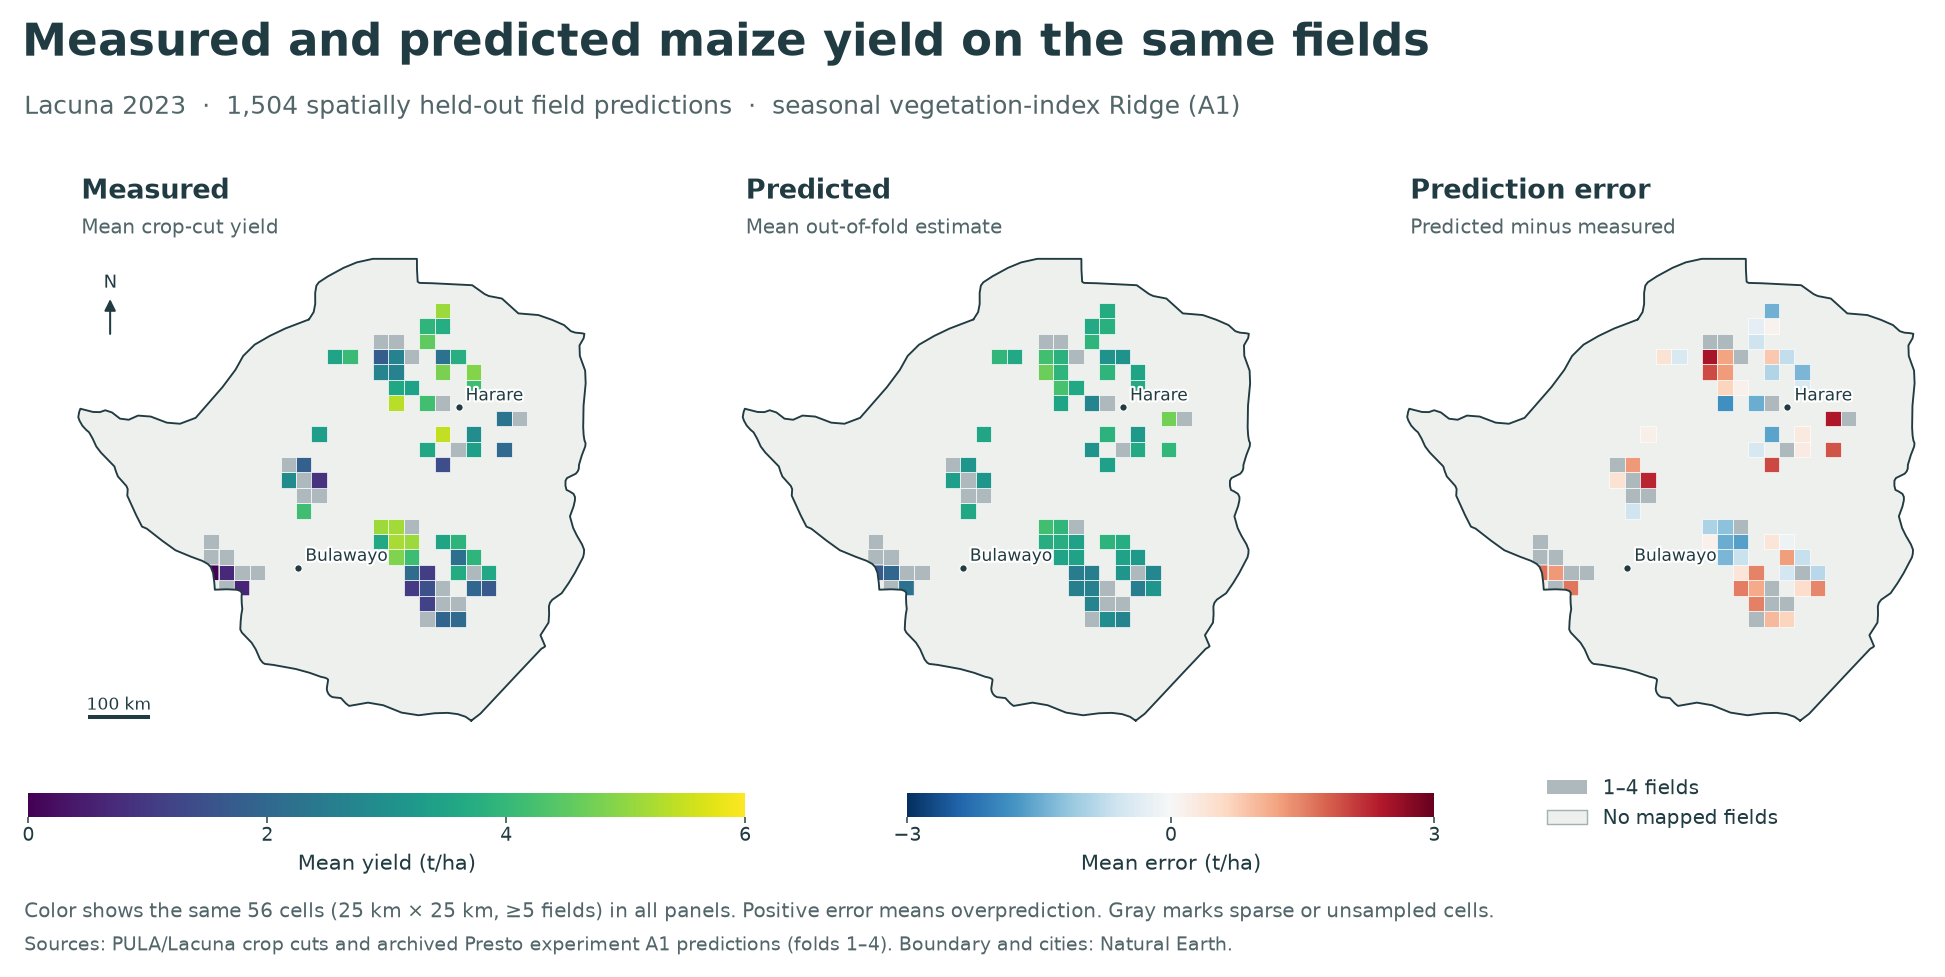

In [4]:
show_file(OUT / "prediction_map.png")

## Yield distributions across harvests

Following the distribution comparison in Jin et al. Fig. 6a, each curve shows the fraction of recorded fields with yield at or below a given value. Every field contributes one observation. The solid lines use the screened catalog. Dashed lines apply the project's v2 primary-label rule before satellite coverage and spatial splits. The 2024 sensitivity is particularly important because 1,874 of its 4,332 records report zero. Their measurement status is uncertain and v2 excludes them from training. The 2022 panel contains ground observations only. [Input records](../data/processed/zimbabwe_weather_v2/harmonized_labels_weather.parquet).

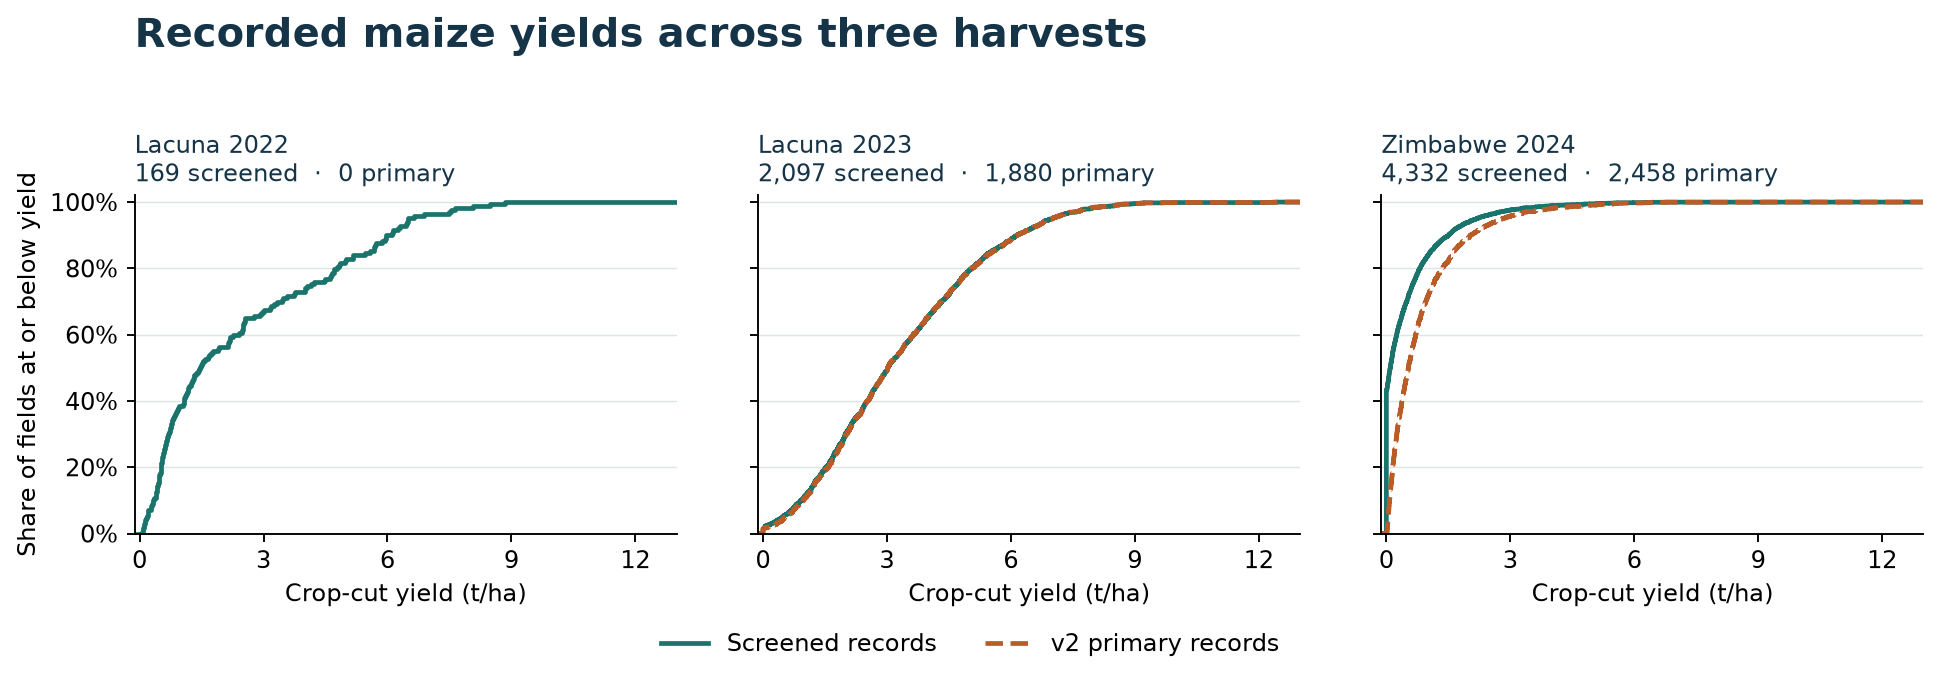

,fields,q05,median,q95
season_year,,,,
2022,169,0.18,1.46,6.50
2023,2097,0.48,3.02,7.00
2024,4332,0.00,0.09,2.18


In [5]:
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

season_names = {2022: "Lacuna 2022", 2023: "Lacuna 2023", 2024: "Zimbabwe 2024"}
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9), sharex=True, sharey=True)
fig.subplots_adjust(left=.07, right=.985, top=.72, bottom=.21, wspace=.15)
fig.suptitle("Recorded maize yields across three harvests", x=.07, y=.99, ha="left",
             fontsize=17, fontweight="bold", color="#163447")
for ax, (year, label) in zip(axes, season_names.items()):
    sample = fields.loc[fields.season_year.eq(year)]
    for pool, color, style in [(sample, "#1A746B", "-"),
                               (sample.loc[sample.include_primary], "#B95C28", "--")]:
        if pool.empty:
            continue
        y, counts = np.unique(pool.yield_t_ha, return_counts=True)
        ax.step(np.r_[-.12, y, 13], np.r_[0, counts.cumsum()/counts.sum(), 1],
                where="post", color=color, linestyle=style, linewidth=2)
    ax.set_title(f"{label}\n{len(sample):,} screened  ·  {sample.include_primary.sum():,} primary",
                 loc="left", fontsize=10, color="#163447")
    ax.grid(axis="y", color="#DDE5E6", linewidth=.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set(xlim=(-.12, 13), ylim=(0, 1.02), xticks=[0, 3, 6, 9, 12], xlabel="Crop-cut yield (t/ha)")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Share of fields at or below yield")
fig.legend([Line2D([], [], color="#1A746B", lw=2), Line2D([], [], color="#B95C28", ls="--", lw=2)],
           ["Screened records", "v2 primary records"], loc="lower center", ncol=2, frameon=False)
export_figure(fig, "yield_distributions.png")

summary = fields.groupby("season_year").yield_t_ha.agg(
    fields="size", q05=lambda s: s.quantile(.05), median="median", q95=lambda s: s.quantile(.95))
display(summary.round(2))

The median recorded yield was 3.02 t/ha for Lacuna 2023 and 0.09 t/ha for the screened 2024 source. The two providers sampled different fields and used different crop-cut protocols. The solid and dashed curves show how sample selection changes the 2024 comparison.

## Satellite observations and model estimates

### Seasonal greenness

Jin et al. used the seasonal course of GCVI, the green chlorophyll vegetation index, in their yield analysis (§4.1.2). We group 1,880 Lacuna 2023 fields by measured harvest yield and show the observed monthly median and interquartile range of GCVI in each group. The count below each month is the number of fields with a usable observation. October and November are gaps. These curves use the original imagery preserved in the corrected v2 handoff table. [Monthly imagery and provenance](../data/processed/zimbabwe_midterm_v2/README.md).

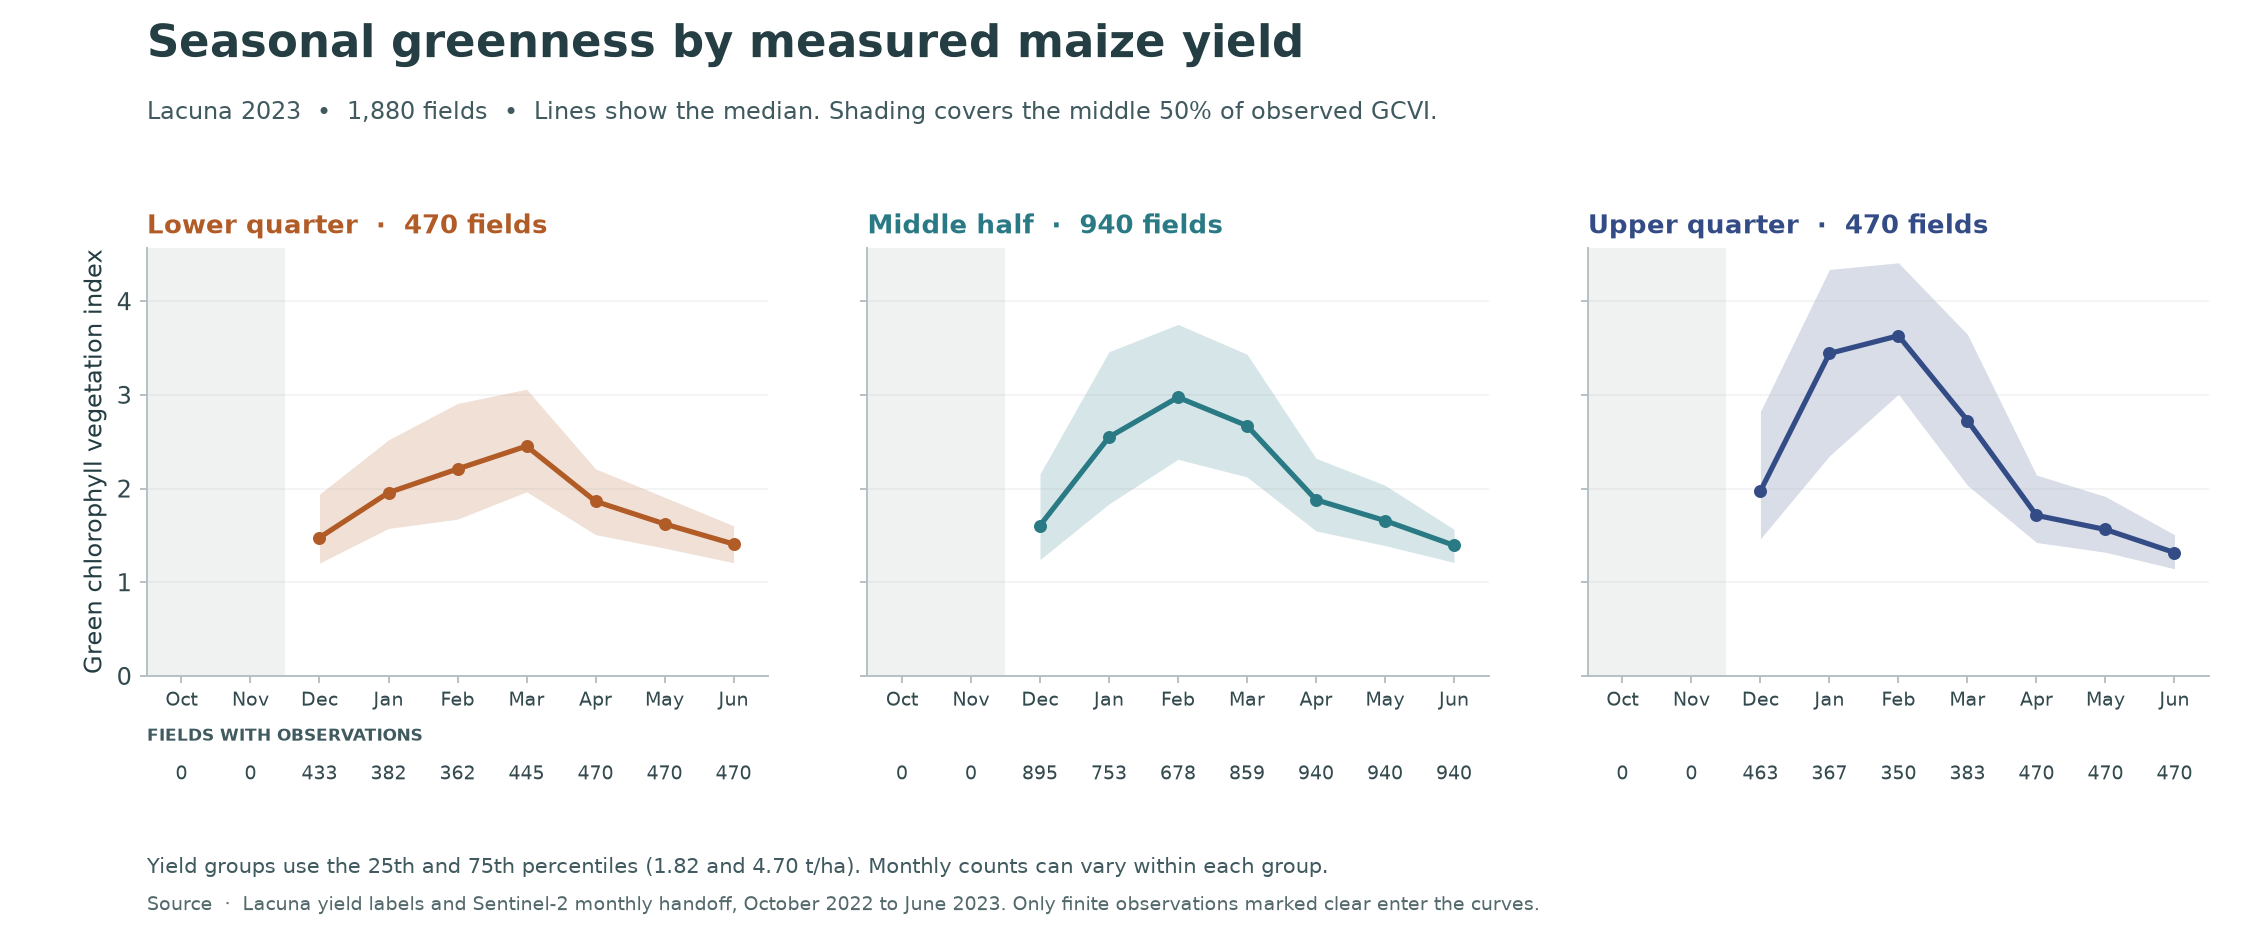

In [6]:
from scripts.paper.atlas_diagnostics import build_diagnostics

diagnostics = build_diagnostics(ROOT, OUT)
show_file(diagnostics["seasonal_gcvi"])

### Agreement with crop cuts at two scales

Jin et al. Fig. 4 compares crop cuts and satellite estimates at district scale. The top row here shows individual Zimbabwe fields. The bottom row averages those same observations within each of the 19 provider administrative units, with equal weight per unit for the area scores. Each dot uses predictions from the **data v2 Presto experiment** on 1,504 development fields. A1 uses seasonal vegetation indices. P0 fits Ridge to frozen Presto embeddings generated by that experiment. These runs allowed fold 0 to supply training fields and scored folds 1–4. The reported R² uses the pooled sum of squared prediction errors at each scale. [Experiment protocol](../experiments/presto_finetune/PLAN.md) · [Saved scores](../experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/scores.csv).

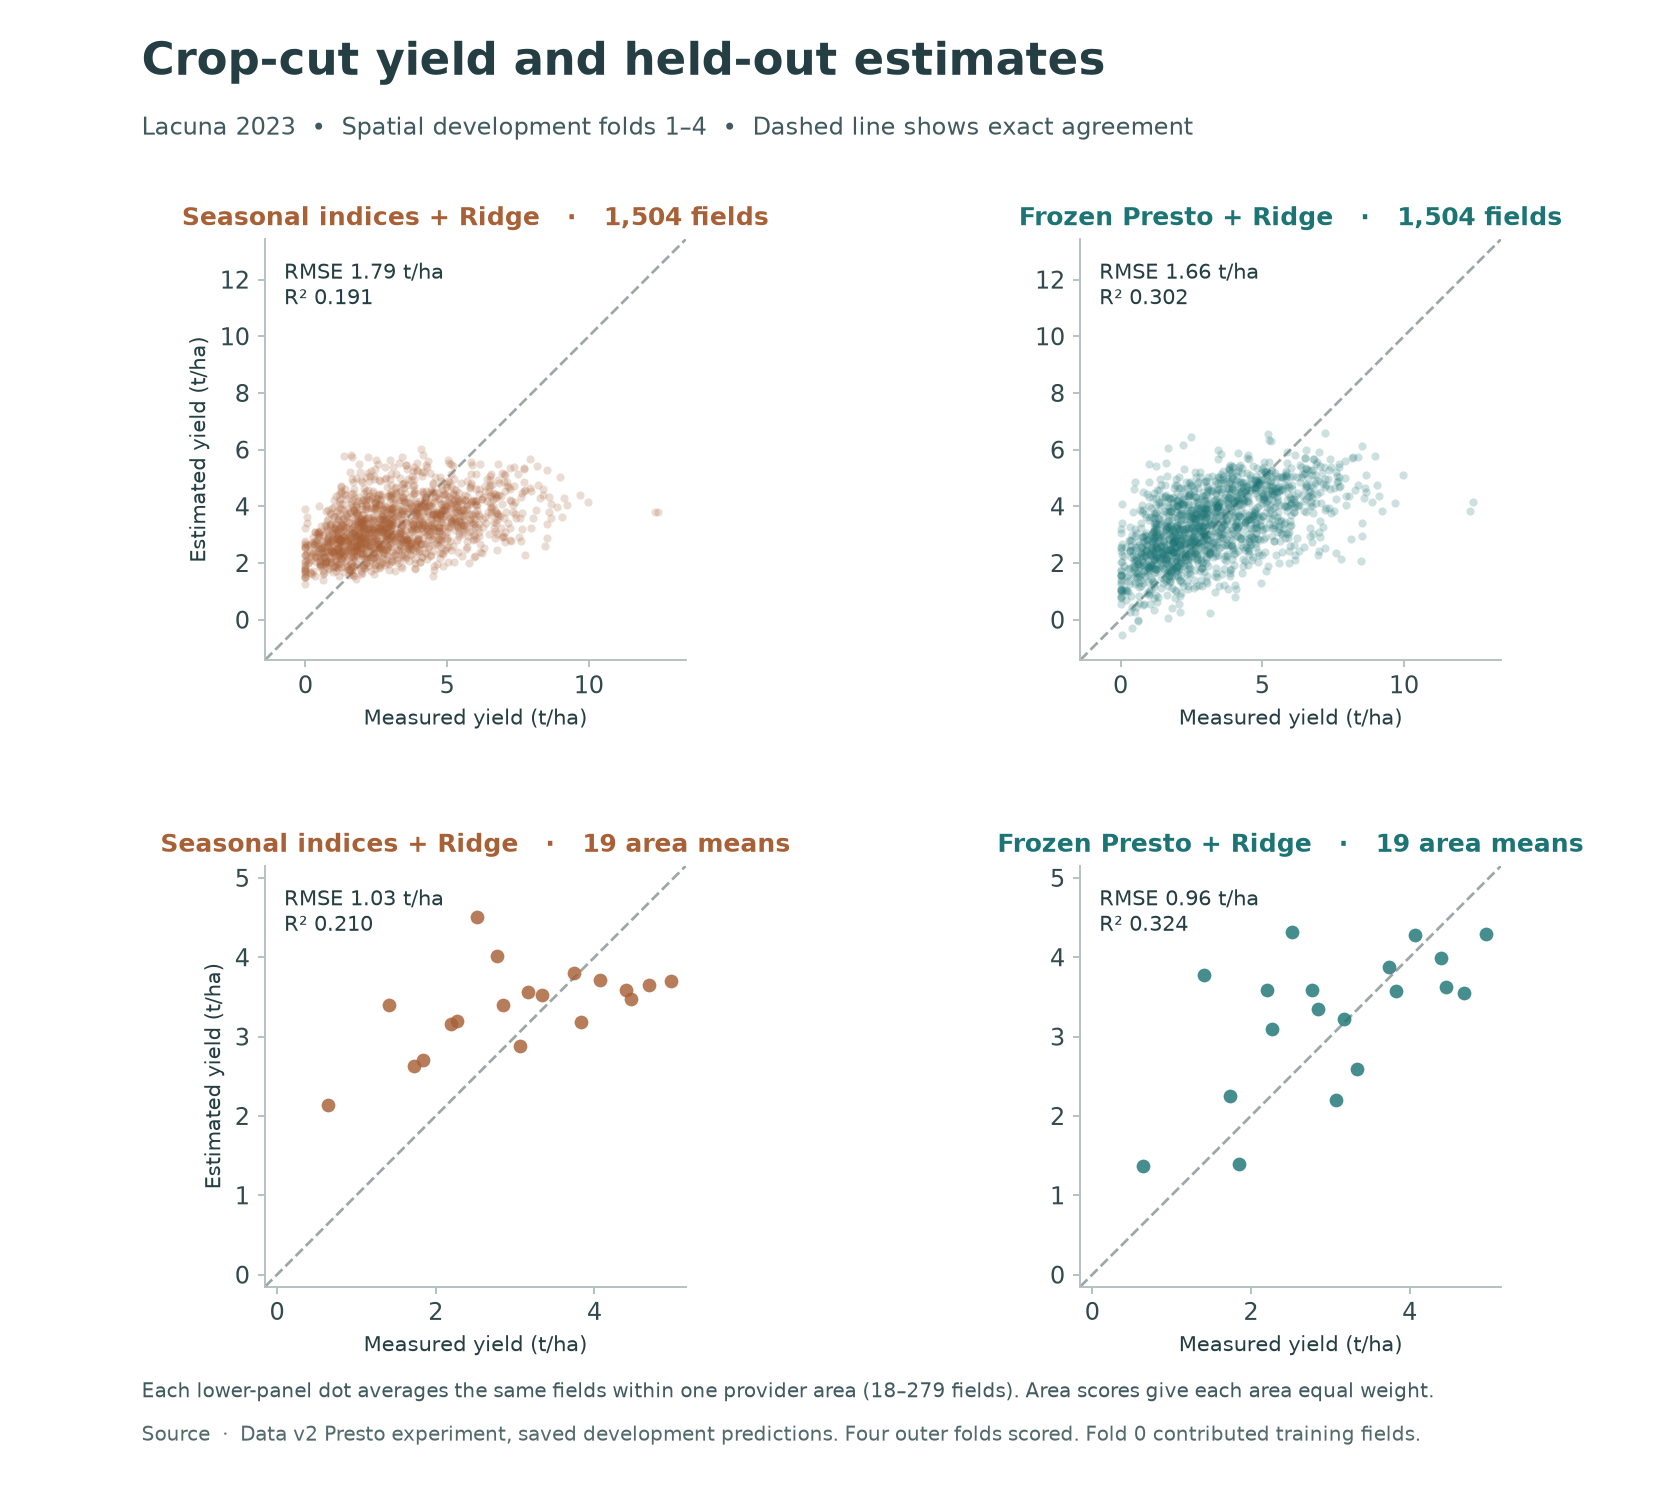

In [7]:
show_file(diagnostics["yield_agreement"])

## How regional weather and measured yield vary together

Jin et al. Fig. 7a compared yield and soil variables. Here the environmental variables are the four seasonal rainfall and temperature features available in Zimbabwe. A square gives the Pearson correlation across sampled NASA POWER cells within a single harvest and provider. We average v2 primary crop-cut yields first, require at least five primary fields per cell, and give each retained cell equal weight. This keeps multiple fields that share a weather estimate from appearing as separate weather observations. The threshold is a display choice. Spatial dependence and differences in the sampled farms affect these descriptive associations. [NASA source and processing](../docs/zimbabwe/METHODS.md#weather-extraction-and-features).

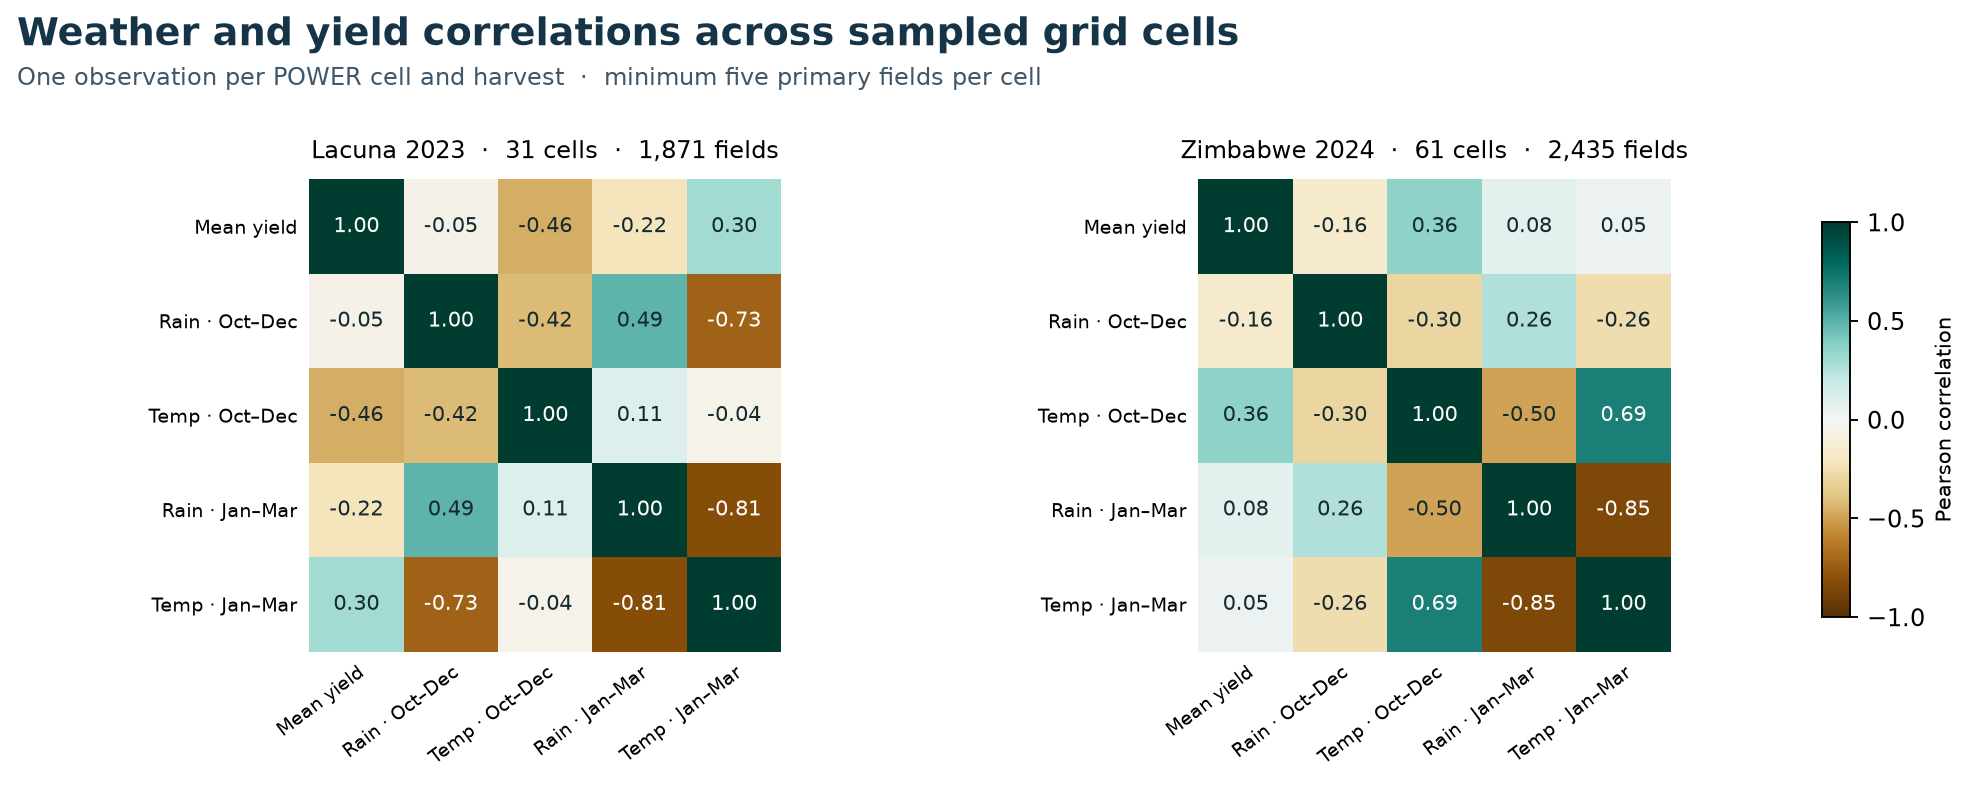

In [8]:
from cropyield.experiments.zimbabwe_weather_compact import early_weather

keys = ["weather_grid_id", "season_year"]
# Use the same October–December calculation as the project's compact-weather experiments.
early = early_weather(pd.read_parquet(weather_dir / "weather_cell_months.parquet"))
weather_cols = {
    "wx_rain_percent_normal_oct_dec": "Rain · Oct–Dec",
    "wx_t2m_anomaly_c_oct_dec": "Temp · Oct–Dec",
    "wx_rain_percent_normal_jan_mar": "Rain · Jan–Mar",
    "wx_t2m_anomaly_c_jan_mar": "Temp · Jan–Mar",
}
primary = fields.loc[fields.include_primary].merge(early, on=keys, validate="many_to_one")
by_cell = primary.groupby(keys)
assert by_cell[list(weather_cols)].nunique(dropna=False).eq(1).all().all()
sampled_cells = by_cell.size().rename("fields").to_frame().join(
    by_cell.yield_t_ha.mean().rename("Mean yield")).join(by_cell[list(weather_cols)].first())
sampled_cells = sampled_cells.loc[sampled_cells.fields.ge(5)].rename(columns=weather_cols).reset_index()
sampled_cells.to_csv(OUT / "weather_yield_cell_means.csv", index=False)

cols = ["Mean yield", *weather_cols.values()]
fig, axes = plt.subplots(1, 2, figsize=(11.8, 5.05))
fig.subplots_adjust(left=.13, right=.89, top=.79, bottom=.24, wspace=.40)
fig.suptitle("Weather and yield correlations across sampled grid cells", x=.025, y=.98,
             ha="left", fontsize=16, fontweight="bold", color="#163447")
fig.text(.025, .90, "One observation per POWER cell and harvest  ·  minimum five primary fields per cell",
         fontsize=10, color="#40576A")
for ax, (year, group) in zip(axes, sampled_cells.groupby("season_year", sort=True)):
    corr = group[cols].corr()
    im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
    ax.set(xticks=range(len(cols)), yticks=range(len(cols)), yticklabels=cols)
    ax.set_xticklabels(cols, rotation=37, ha="right", rotation_mode="anchor")
    ax.tick_params(labelsize=8, length=0, pad=5)
    ax.set_title(f"{season_names[year]}  ·  {len(group)} cells  ·  {group.fields.sum():,} fields",
                 fontsize=10, pad=9)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if abs(v) >= .60 else "#142A2E", fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
bar = fig.colorbar(im, cax=fig.add_axes([.925, .28, .014, .46]), ticks=[-1, -.5, 0, .5, 1])
bar.set_label("Pearson correlation", fontsize=9)
export_figure(fig, "weather_yield_correlations.png")

Here *rain* is percent of the 1991–2020 normal and *temperature* is departure from the normal in °C. October–December belongs to the calendar year before the harvest. Each coefficient describes variation across the sampled cells within one season. Weather, field management and sampling locations can all vary together. [Cell-level data behind the figure](../results/visual_atlas/weather_yield_cell_means.csv).

## Repository figure gallery

The gallery inventories the tracked project at the start of this atlas, revision [8de629a](https://github.com/FelixYu120/DSC-291-Final-Project/tree/8de629a). It covers standalone images, images embedded in active and archived notebooks, project diagrams, and provider illustrations. Source files that contain identical images share a gallery ID. The gallery also reconstructs report and Presto figures where the plotting code and numeric data were saved separately.

Use the contact sheets to browse. The links below them give the original file and, for notebook figures, the cell and output number. The CSV indexes every source occurrence. For a full-size view in Jupyter set the figure ID in the last cell. Rebuilding this section uses local Git history including revision 8de629a. [Full source index](../results/visual_atlas/figure_inventory.csv).

In [9]:
from scripts.paper.visualization_gallery import GROUPS, collect_gallery, show_gallery, show_figure

gallery = collect_gallery(ROOT)
gallery.write_manifest(OUT / "figure_inventory.csv")
print(f"{len(gallery.items)} unique figures · {len(gallery.rows)} source occurrences")
display(pd.Series(gallery.counts(), name="Unique figure previews").to_frame())

106 unique figures · 118 source occurrences


,Unique figure previews
Standalone project figures,16
Archived notebook figures,26
Notebook figures,27
Archived project diagrams,3
Provider documentation figures,12
Reconstructed v2 report figures,4
Reconstructed Presto diagnostics,18


### Standalone project figures

16 unique previews · 16 figures referenced in this section.

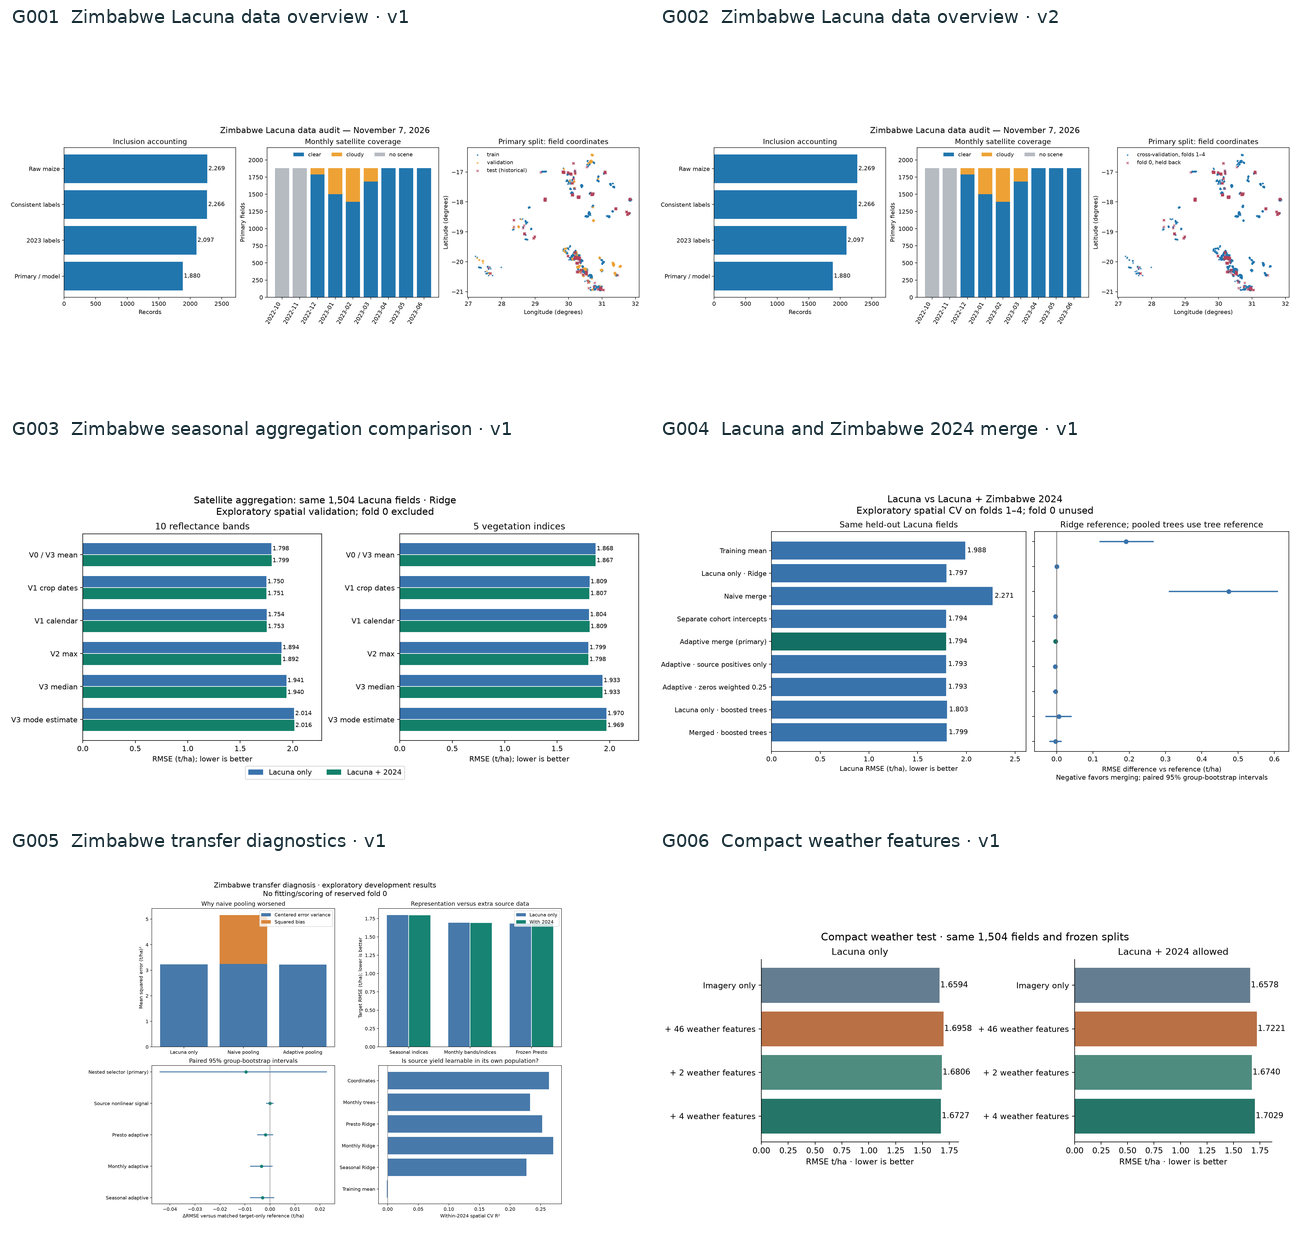

- **G001** [data_overview.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/processed/zimbabwe_midterm_v1/data_overview.png)
- **G002** [data_overview.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/processed/zimbabwe_midterm_v2/data_overview.png)
- **G003** [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_aggregation_v1/comparison.png)
- **G004** [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_merge_v1/comparison.png)
- **G005** [diagnosis.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_transfer_diagnosis_v1/diagnosis.png)
- **G006** [compact_weather_comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_weather_compact_v1/compact_weather_comparison.png) · [data_guide_2_zimbabwe.ipynb · cell 41, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

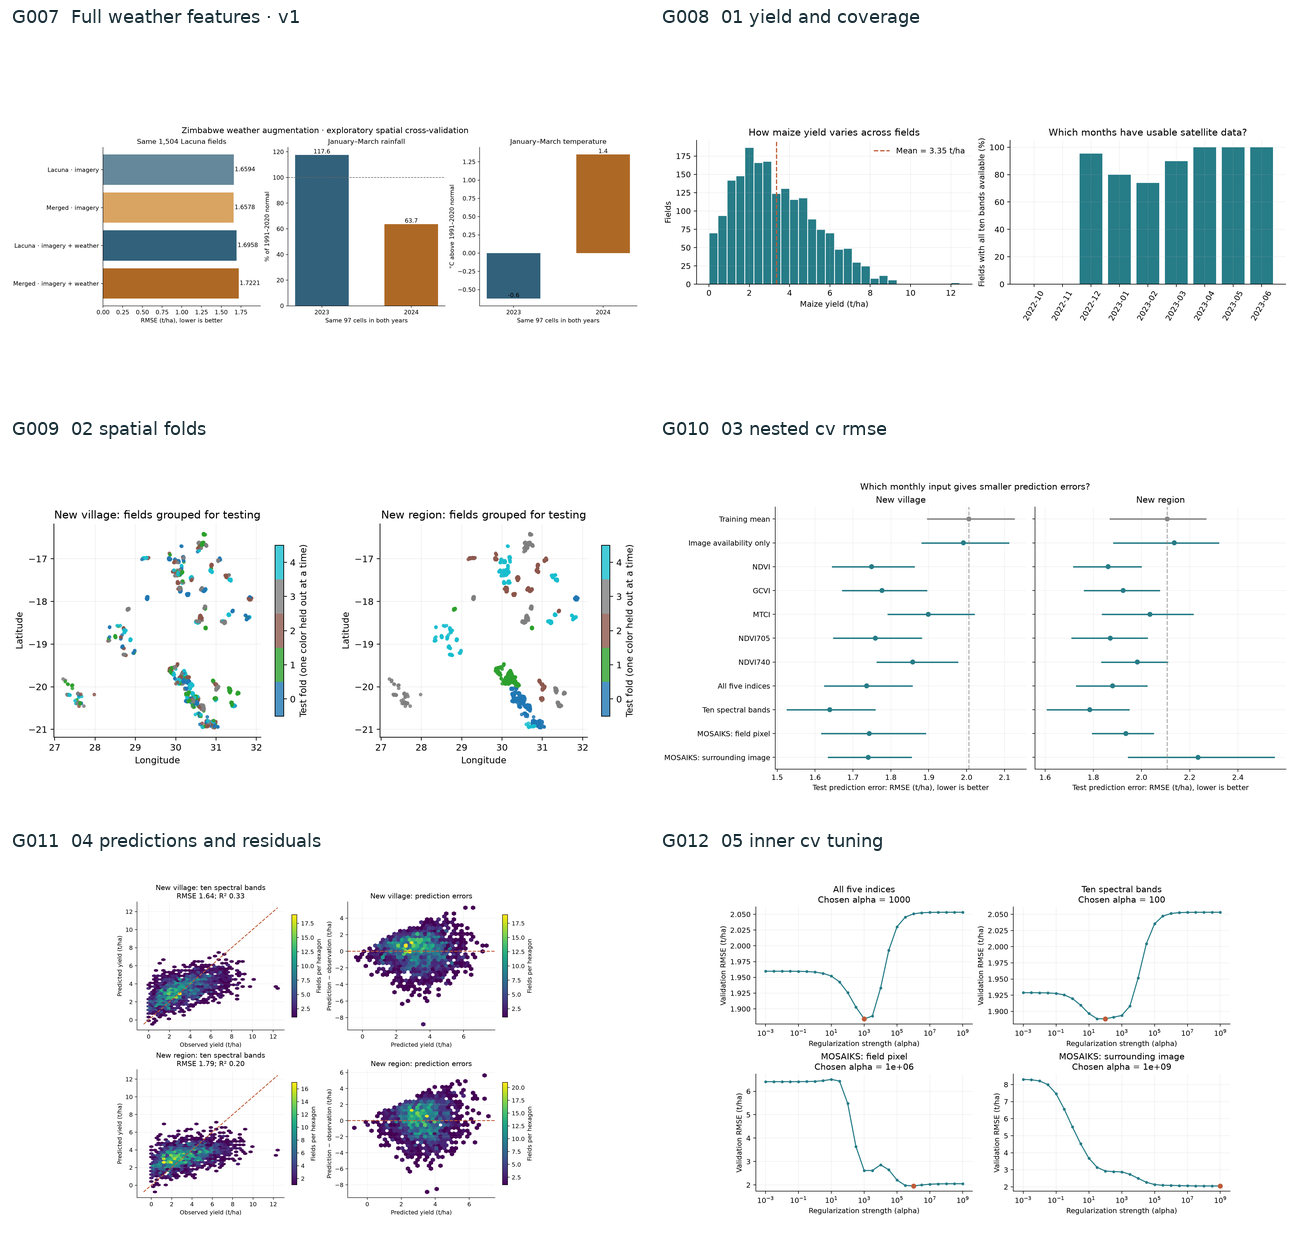

- **G007** [weather_comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_weather_v1/weather_comparison.png)
- **G008** [01_yield_and_coverage.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/01_yield_and_coverage.png)
- **G009** [02_spatial_folds.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/02_spatial_folds.png)
- **G010** [03_nested_cv_rmse.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/03_nested_cv_rmse.png)
- **G011** [04_predictions_and_residuals.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/04_predictions_and_residuals.png)
- **G012** [05_inner_cv_tuning.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/05_inner_cv_tuning.png)

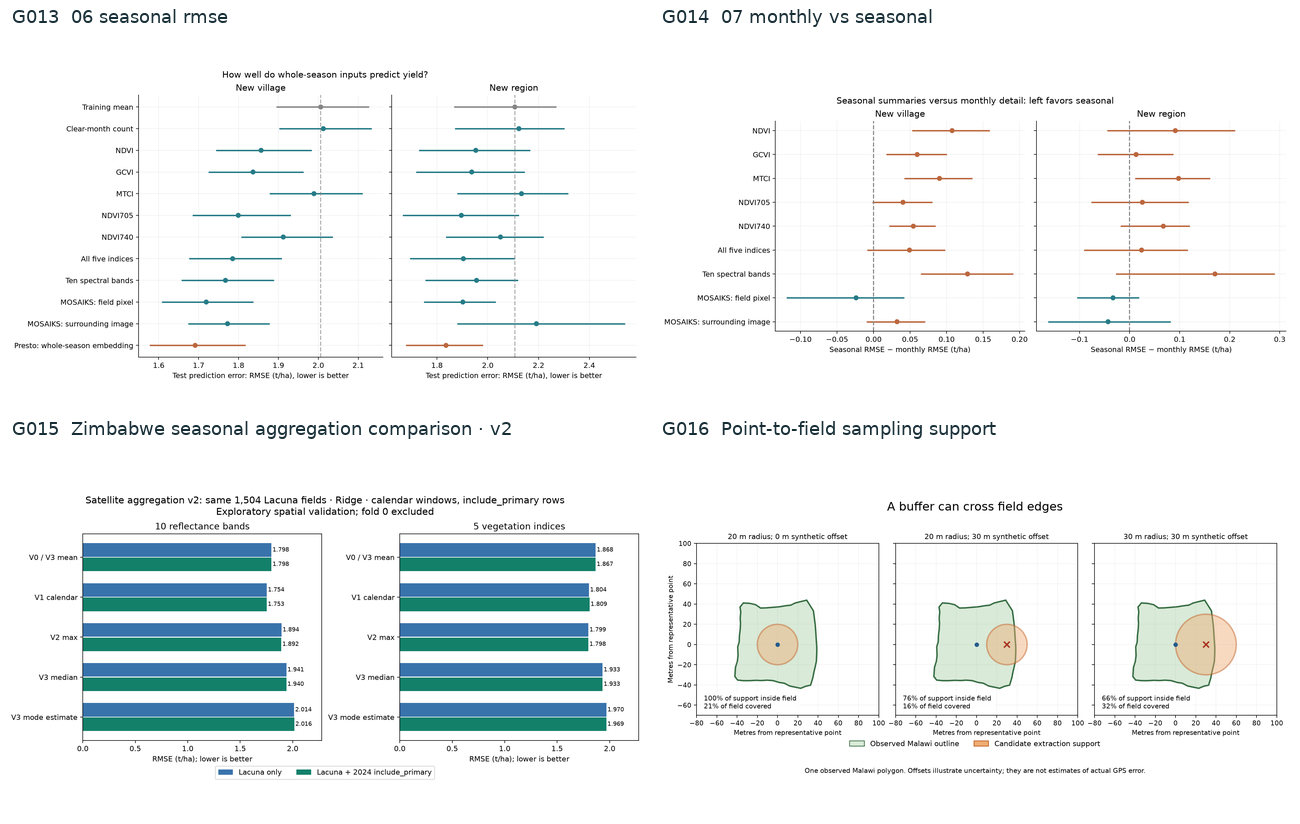

- **G013** [06_seasonal_rmse.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/06_seasonal_rmse.png)
- **G014** [07_monthly_vs_seasonal.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/07_monthly_vs_seasonal.png)
- **G015** [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/aggregation_v2/comparison.png)
- **G016** [point_area_example.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/quality_remediation/point_area_example.png) · [data_quality_review.ipynb · cell 30, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

In [10]:
show_gallery(gallery, "Standalone project figures")

### Notebook figures

27 unique previews · 29 figures referenced in this section.

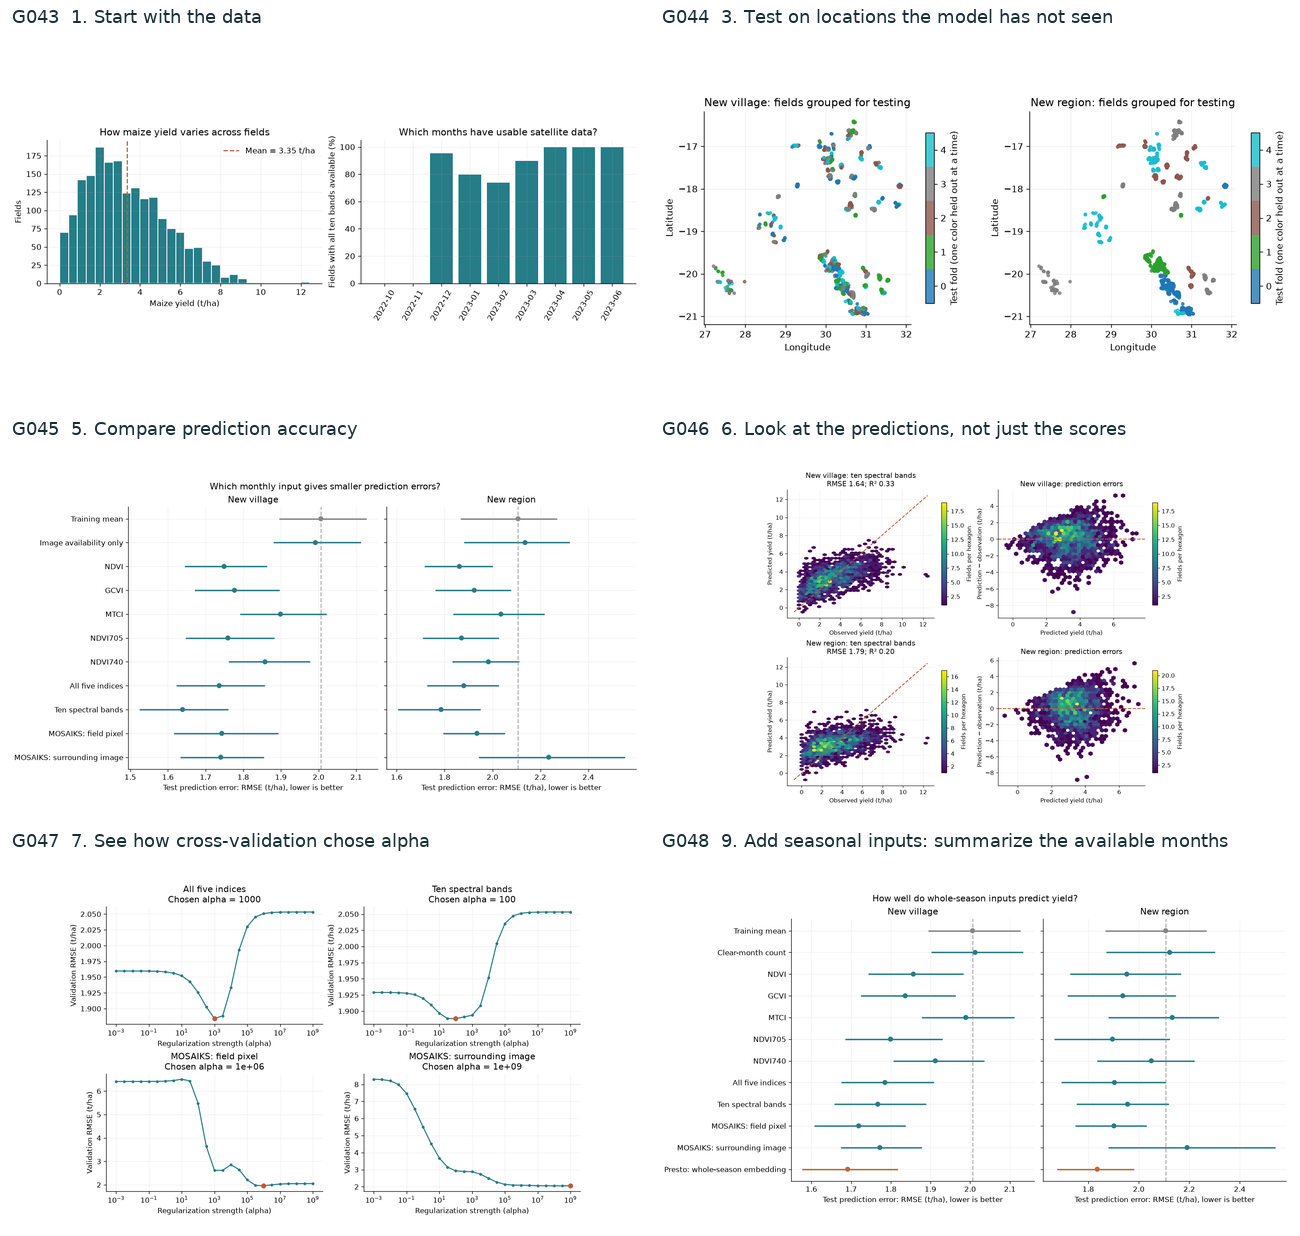

- **G043** [baselines.ipynb · cell 6, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)
- **G044** [baselines.ipynb · cell 12, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)
- **G045** [baselines.ipynb · cell 21, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)
- **G046** [baselines.ipynb · cell 24, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)
- **G047** [baselines.ipynb · cell 27, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)
- **G048** [baselines.ipynb · cell 36, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

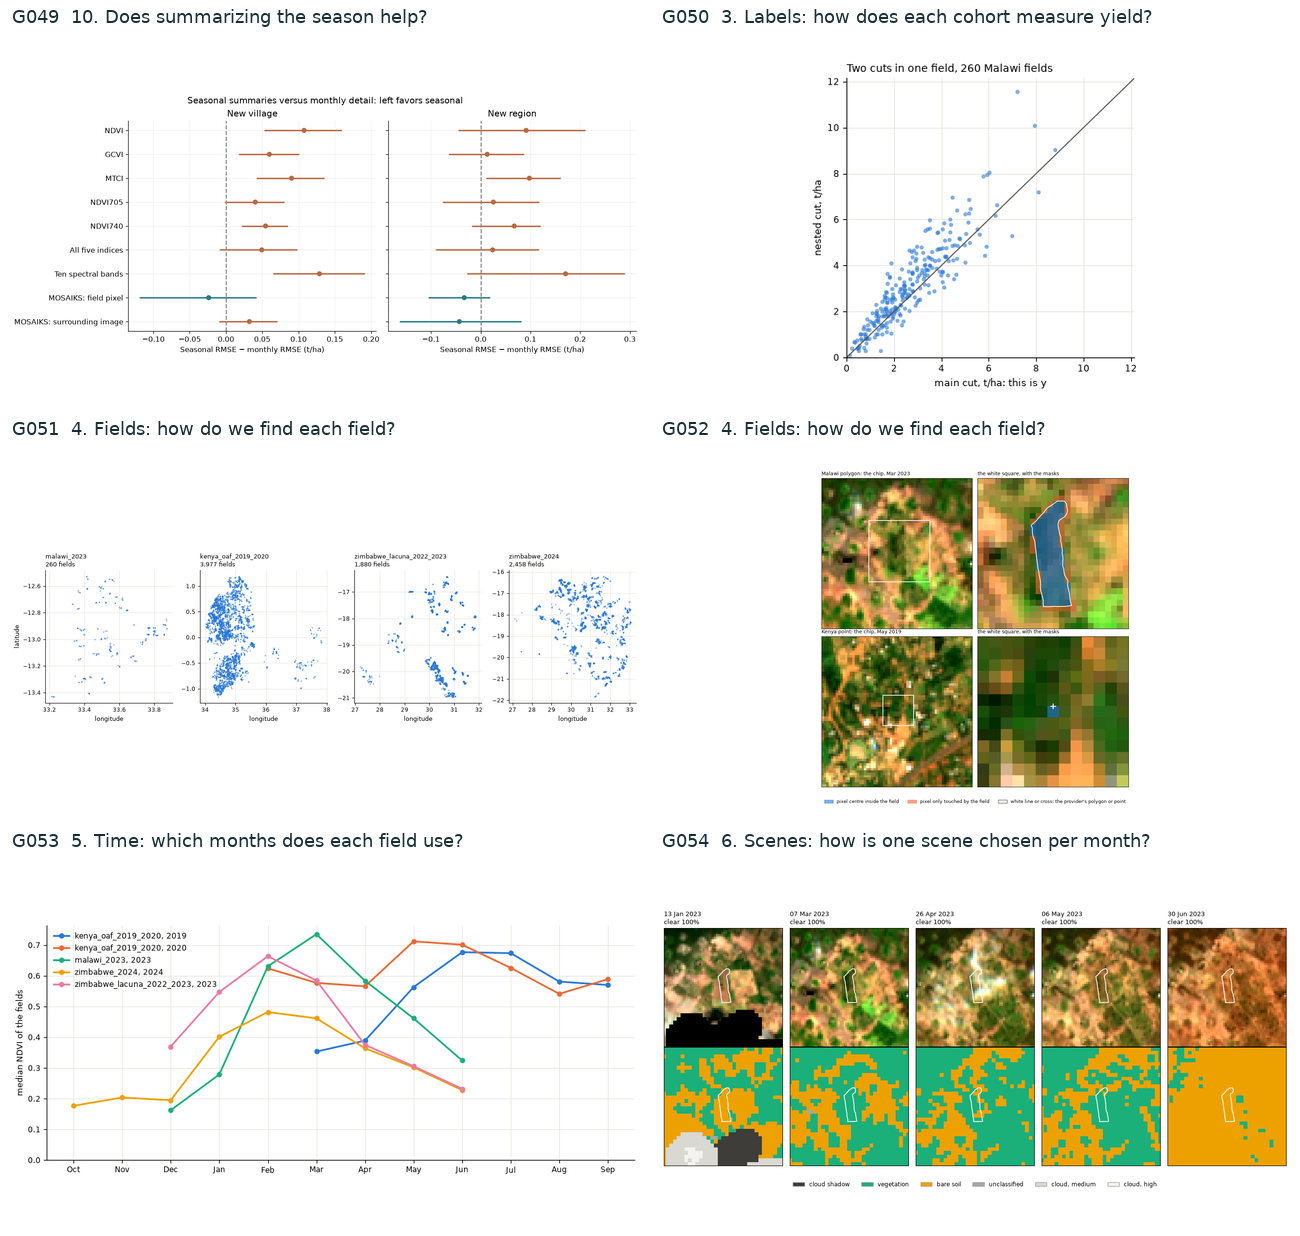

- **G049** [baselines.ipynb · cell 38, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)
- **G050** [data_guide.ipynb · cell 35, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G051** [data_guide.ipynb · cell 37, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G052** [data_guide.ipynb · cell 41, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G053** [data_guide.ipynb · cell 46, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G054** [data_guide.ipynb · cell 52, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

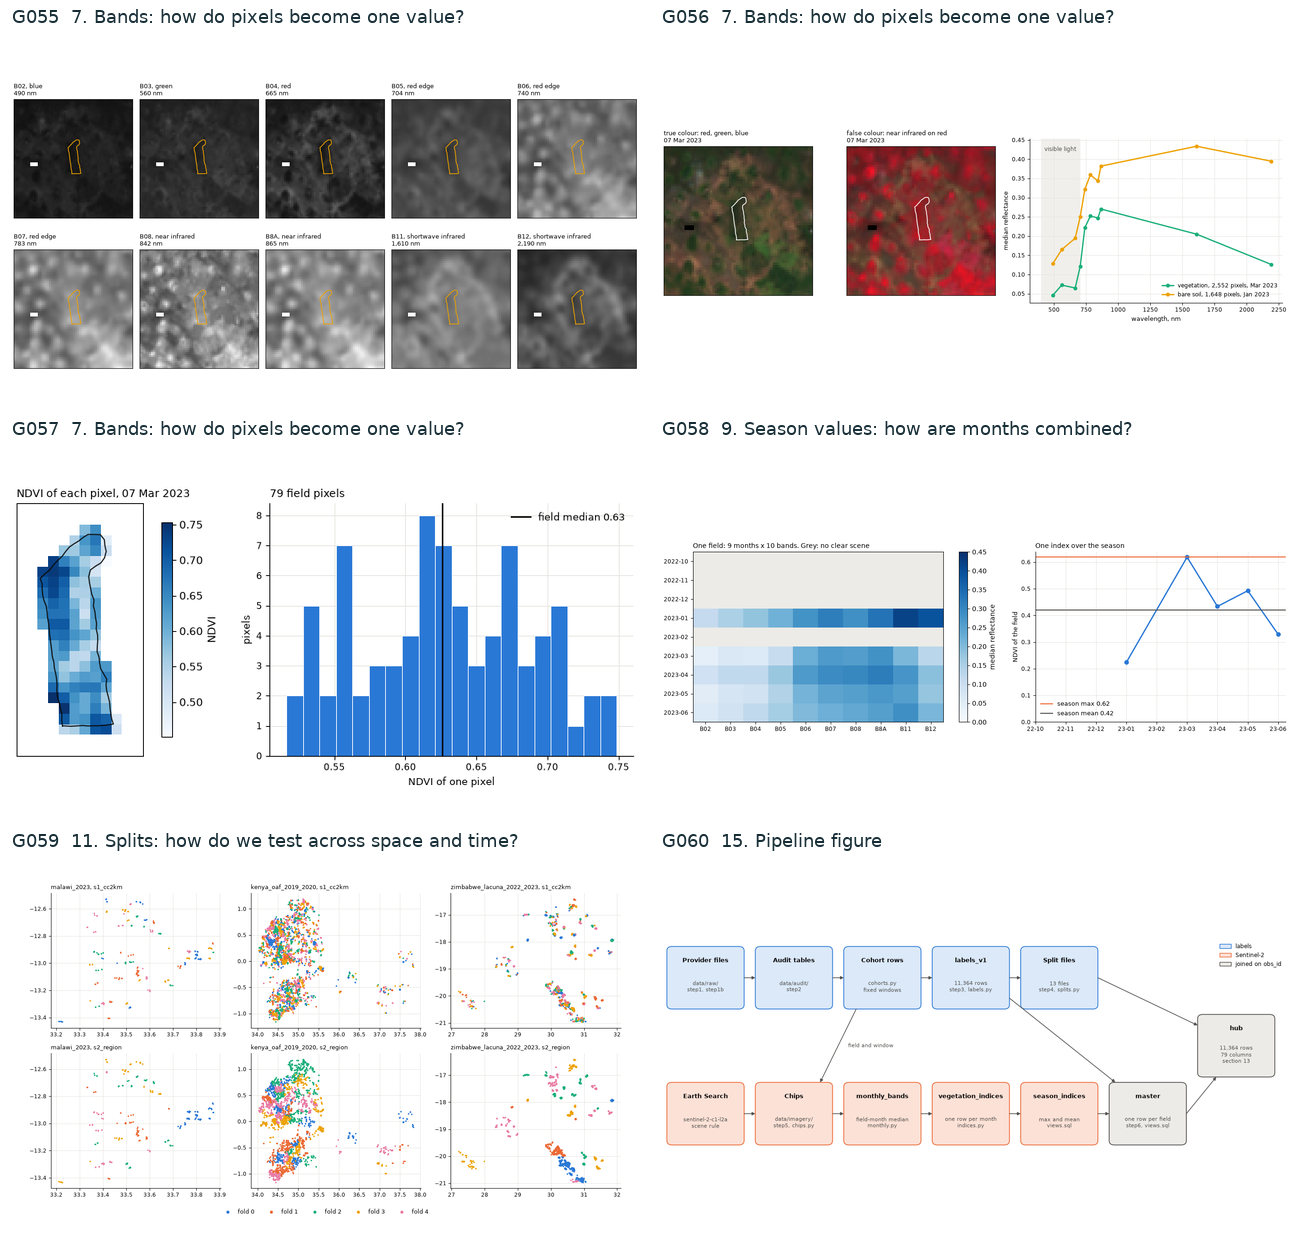

- **G055** [data_guide.ipynb · cell 56, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G056** [data_guide.ipynb · cell 58, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G057** [data_guide.ipynb · cell 61, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G058** [data_guide.ipynb · cell 70, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G059** [data_guide.ipynb · cell 80, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G060** [data_guide.ipynb · cell 94, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

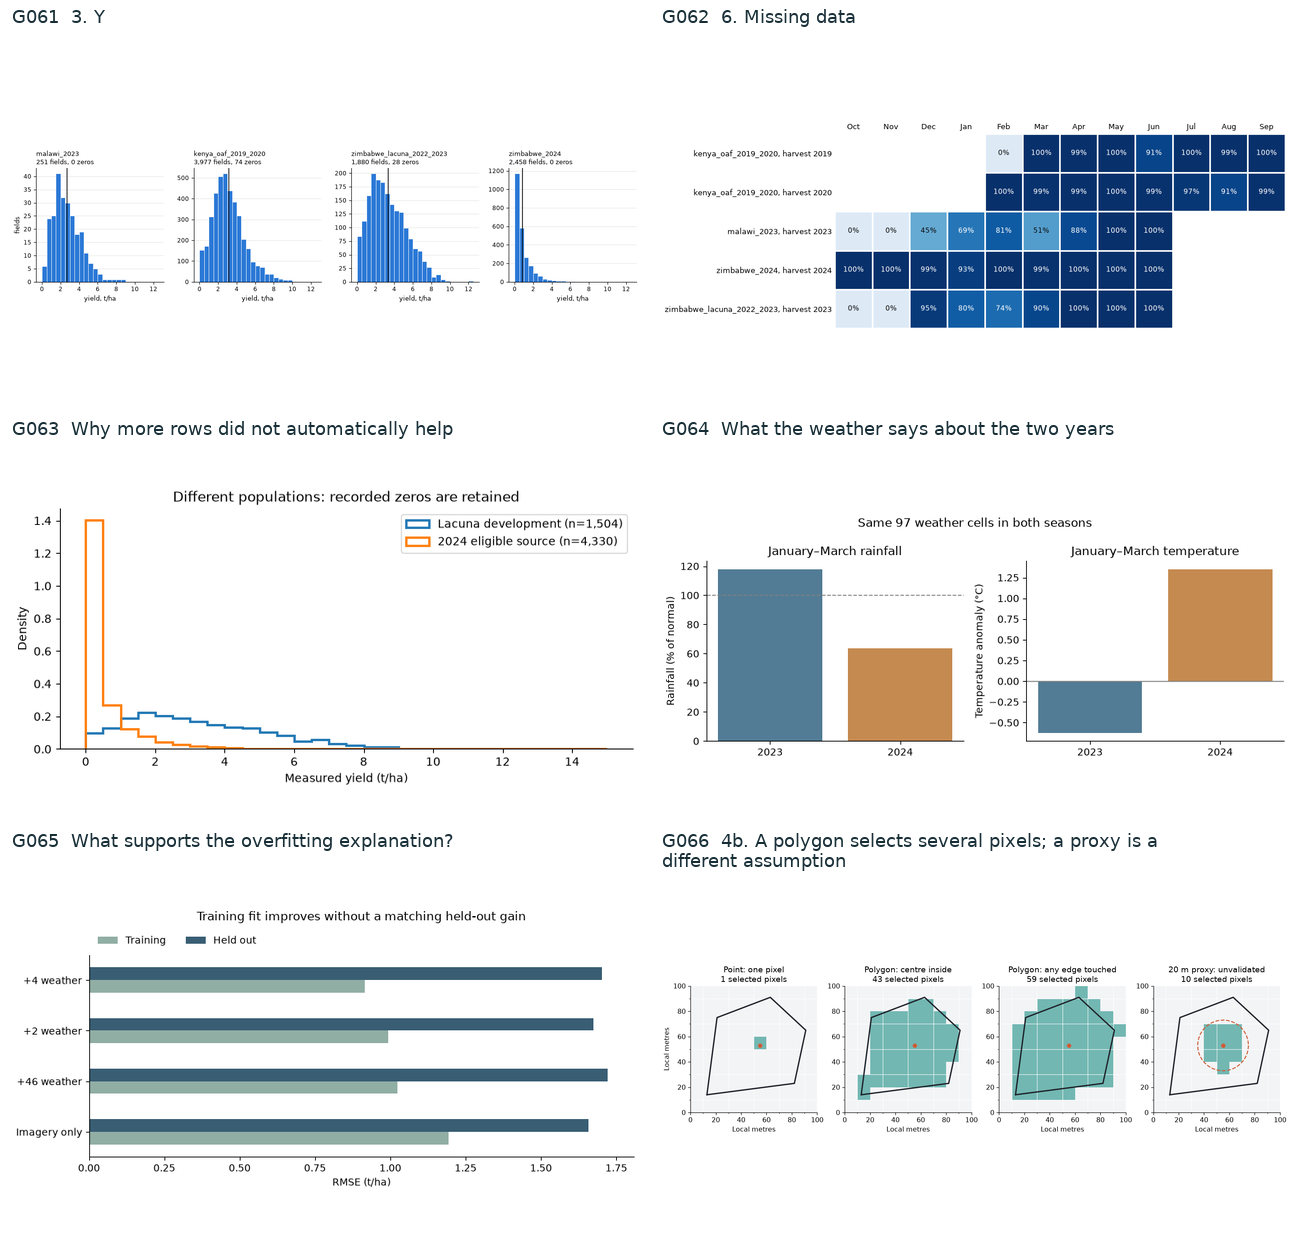

- **G061** [data_guide.ipynb · cell 102, output 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G062** [data_guide.ipynb · cell 109, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)
- **G063** [data_guide_2_zimbabwe.ipynb · cell 20, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)
- **G064** [data_guide_2_zimbabwe.ipynb · cell 38, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)
- **G065** [data_guide_2_zimbabwe.ipynb · cell 43, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)
- **G066** [data_quality_review.ipynb · cell 17, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

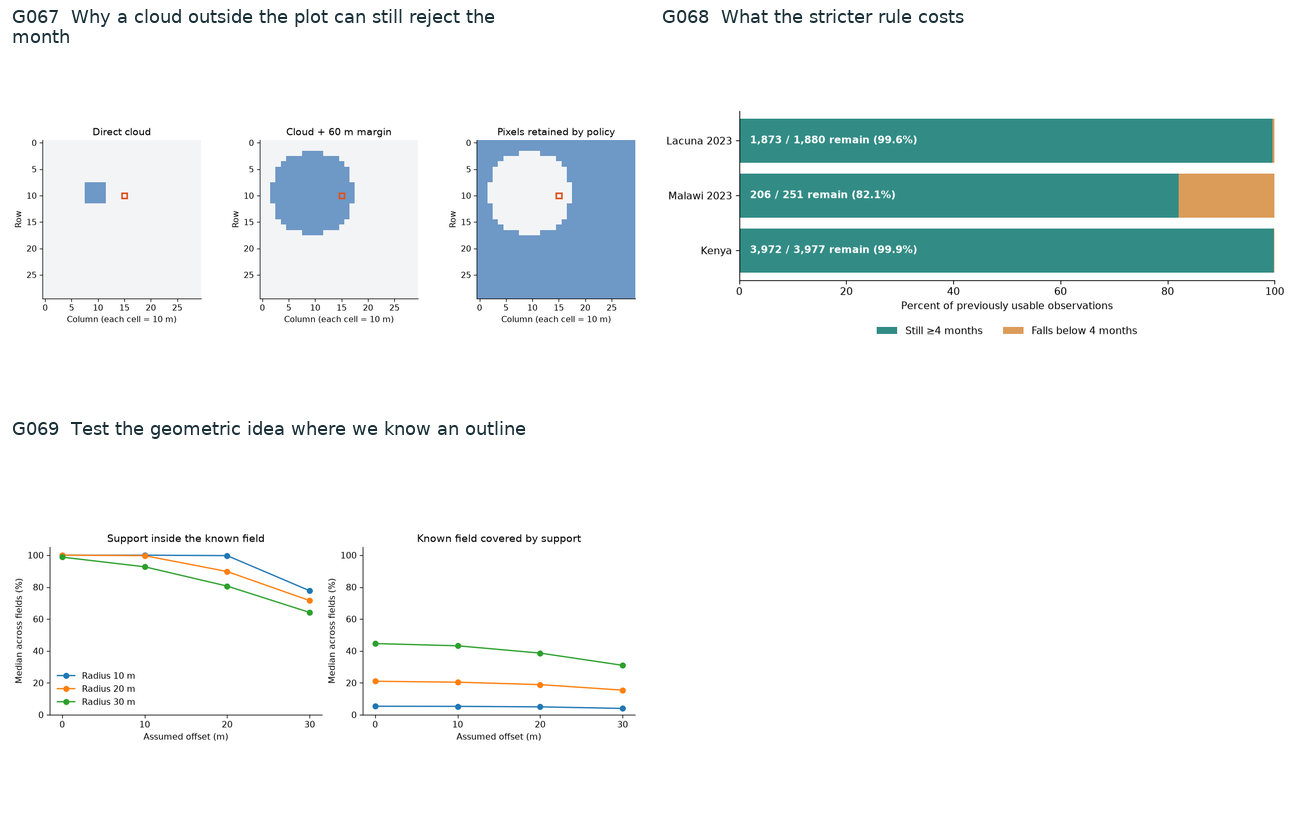

- **G067** [data_quality_review.ipynb · cell 23, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)
- **G068** [data_quality_review.ipynb · cell 25, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)
- **G069** [data_quality_review.ipynb · cell 28, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

In [11]:
show_gallery(gallery, "Notebook figures")

### Archived notebook figures

26 unique previews · 26 figures referenced in this section.

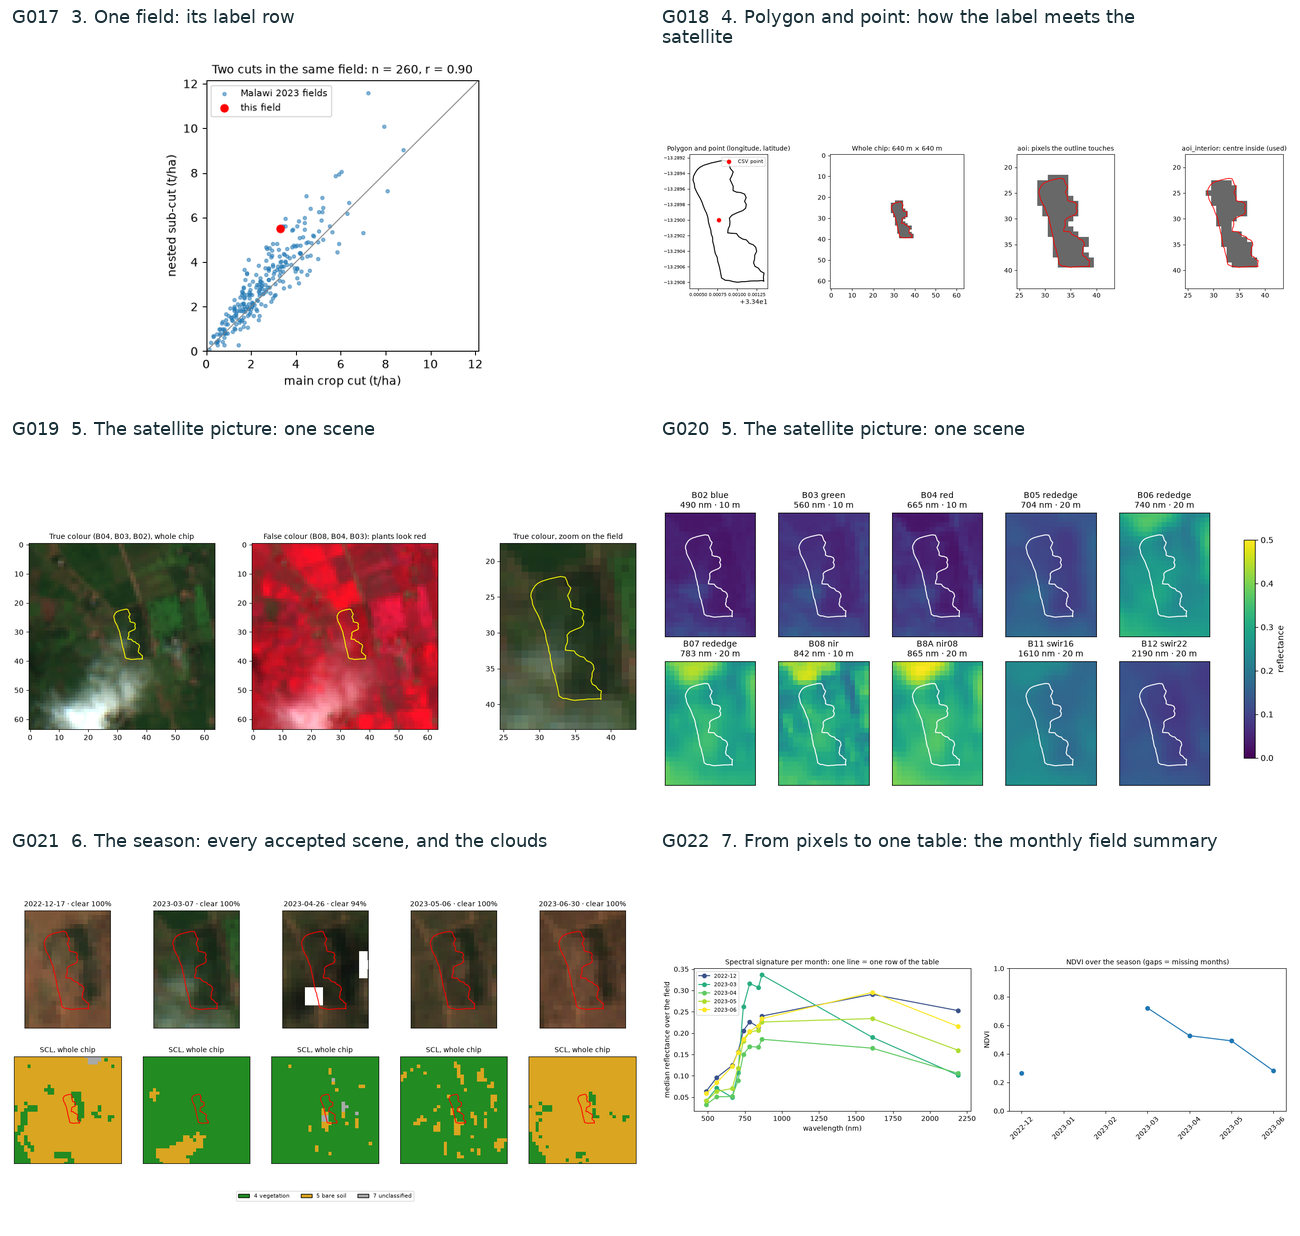

- **G017** [00_data_tour.ipynb · cell 8, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)
- **G018** [00_data_tour.ipynb · cell 10, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)
- **G019** [00_data_tour.ipynb · cell 13, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)
- **G020** [00_data_tour.ipynb · cell 13, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)
- **G021** [00_data_tour.ipynb · cell 16, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)
- **G022** [00_data_tour.ipynb · cell 21, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

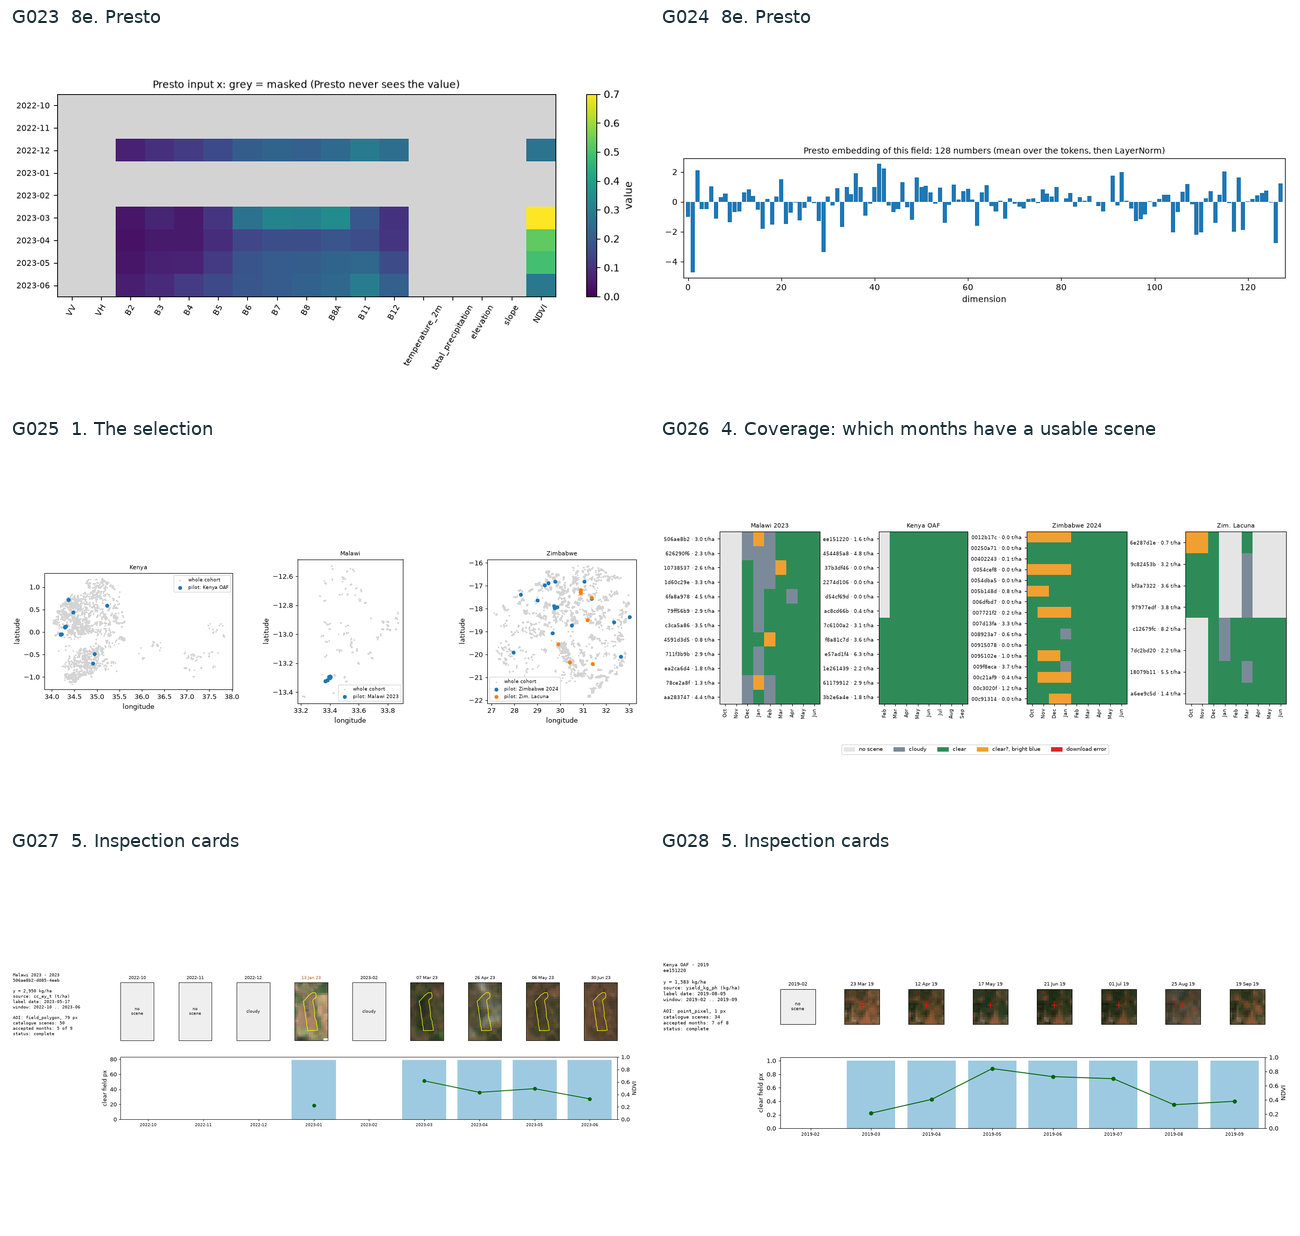

- **G023** [00_data_tour.ipynb · cell 31, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)
- **G024** [00_data_tour.ipynb · cell 34, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)
- **G025** [02_pilot48.ipynb · cell 5, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G026** [02_pilot48.ipynb · cell 11, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G027** [02_pilot48.ipynb · cell 13, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G028** [02_pilot48.ipynb · cell 13, output 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

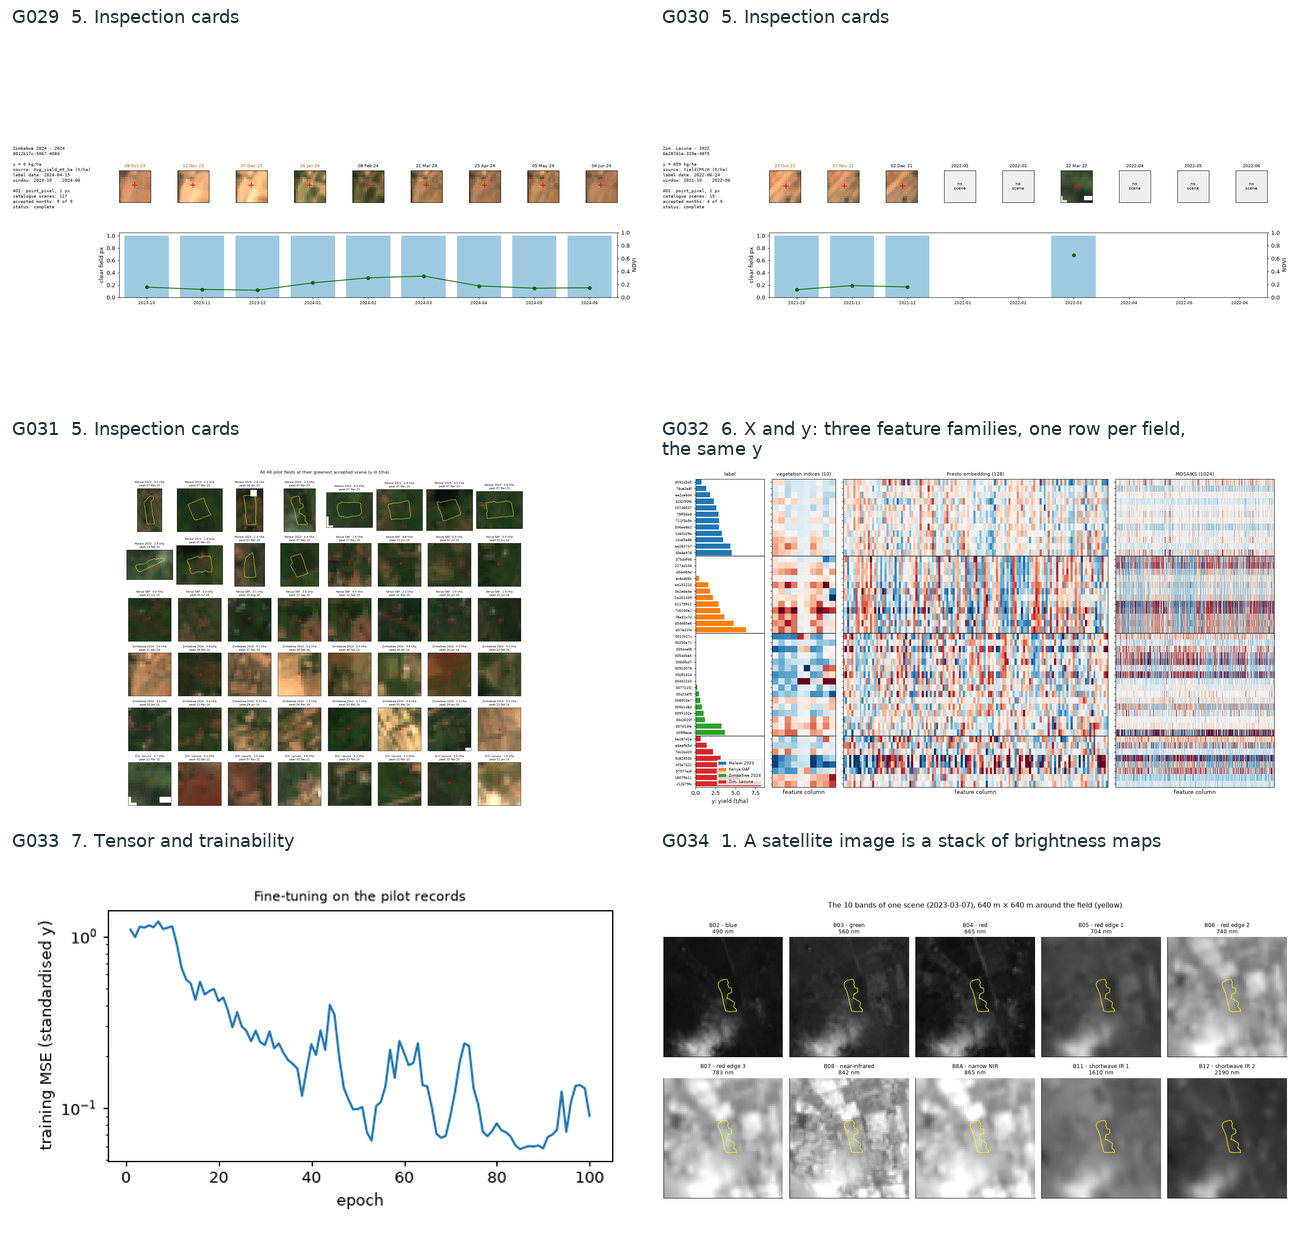

- **G029** [02_pilot48.ipynb · cell 13, output 4](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G030** [02_pilot48.ipynb · cell 13, output 5](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G031** [02_pilot48.ipynb · cell 14, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G032** [02_pilot48.ipynb · cell 18, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G033** [02_pilot48.ipynb · cell 22, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)
- **G034** [03_how_the_data_works.ipynb · cell 4, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

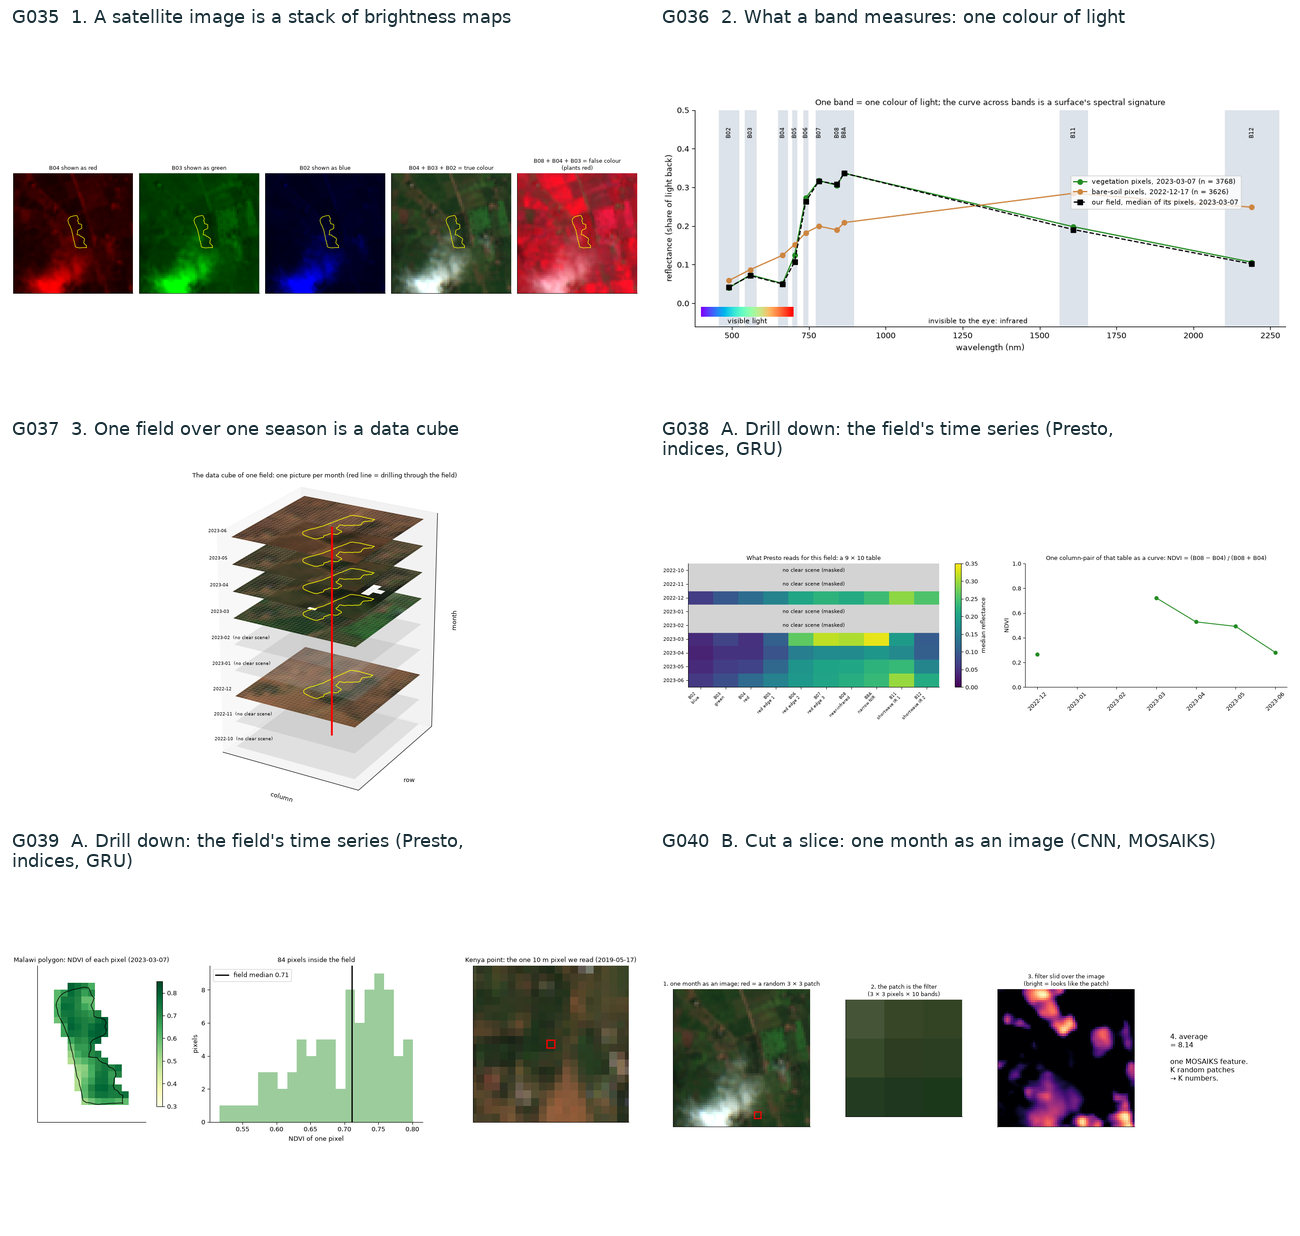

- **G035** [03_how_the_data_works.ipynb · cell 6, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)
- **G036** [03_how_the_data_works.ipynb · cell 8, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)
- **G037** [03_how_the_data_works.ipynb · cell 10, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)
- **G038** [03_how_the_data_works.ipynb · cell 12, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)
- **G039** [03_how_the_data_works.ipynb · cell 14, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)
- **G040** [03_how_the_data_works.ipynb · cell 16, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

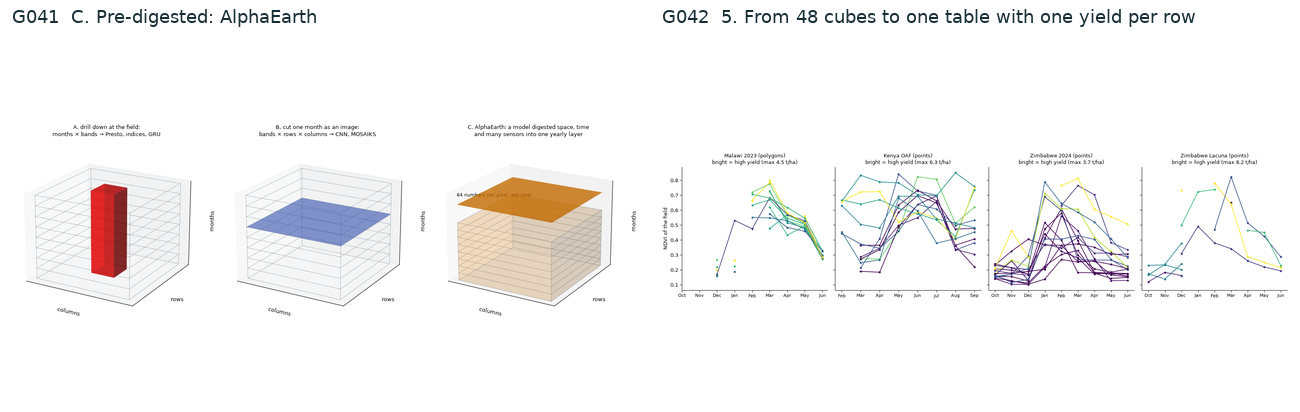

- **G041** [03_how_the_data_works.ipynb · cell 18, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)
- **G042** [03_how_the_data_works.ipynb · cell 20, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

In [12]:
show_gallery(gallery, "Archived notebook figures")

### Archived project diagrams

3 unique previews · 3 figures referenced in this section.

**G070 · From field observations to held-out yield estimates**

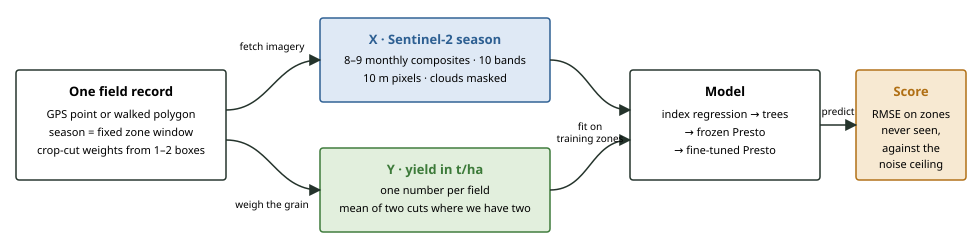

**G071 · From one field to satellite inputs and a yield label**

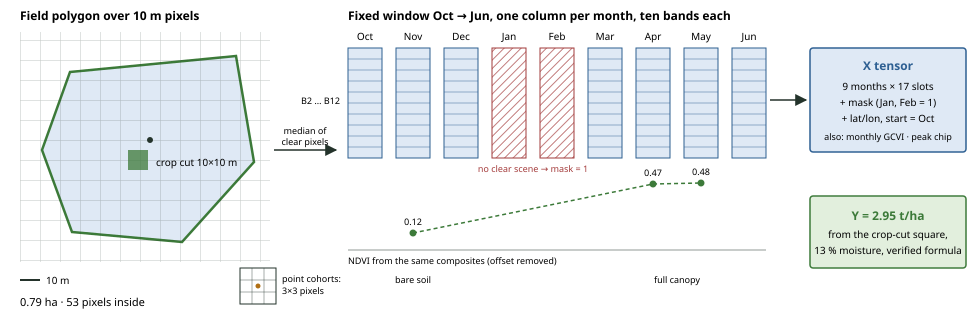

**G072 · Decision gates in the original experiment plan**

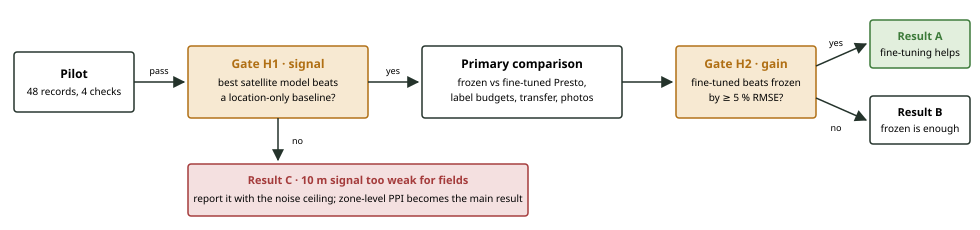

- **G070** [project_map_2026-10-25.html · diagram 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)
- **G071** [project_map_2026-10-25.html · diagram 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)
- **G072** [project_map_2026-10-25.html · diagram 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)

In [13]:
show_gallery(gallery, "Archived project diagrams")

### Provider documentation figures

12 unique previews · 12 figures referenced in this section.

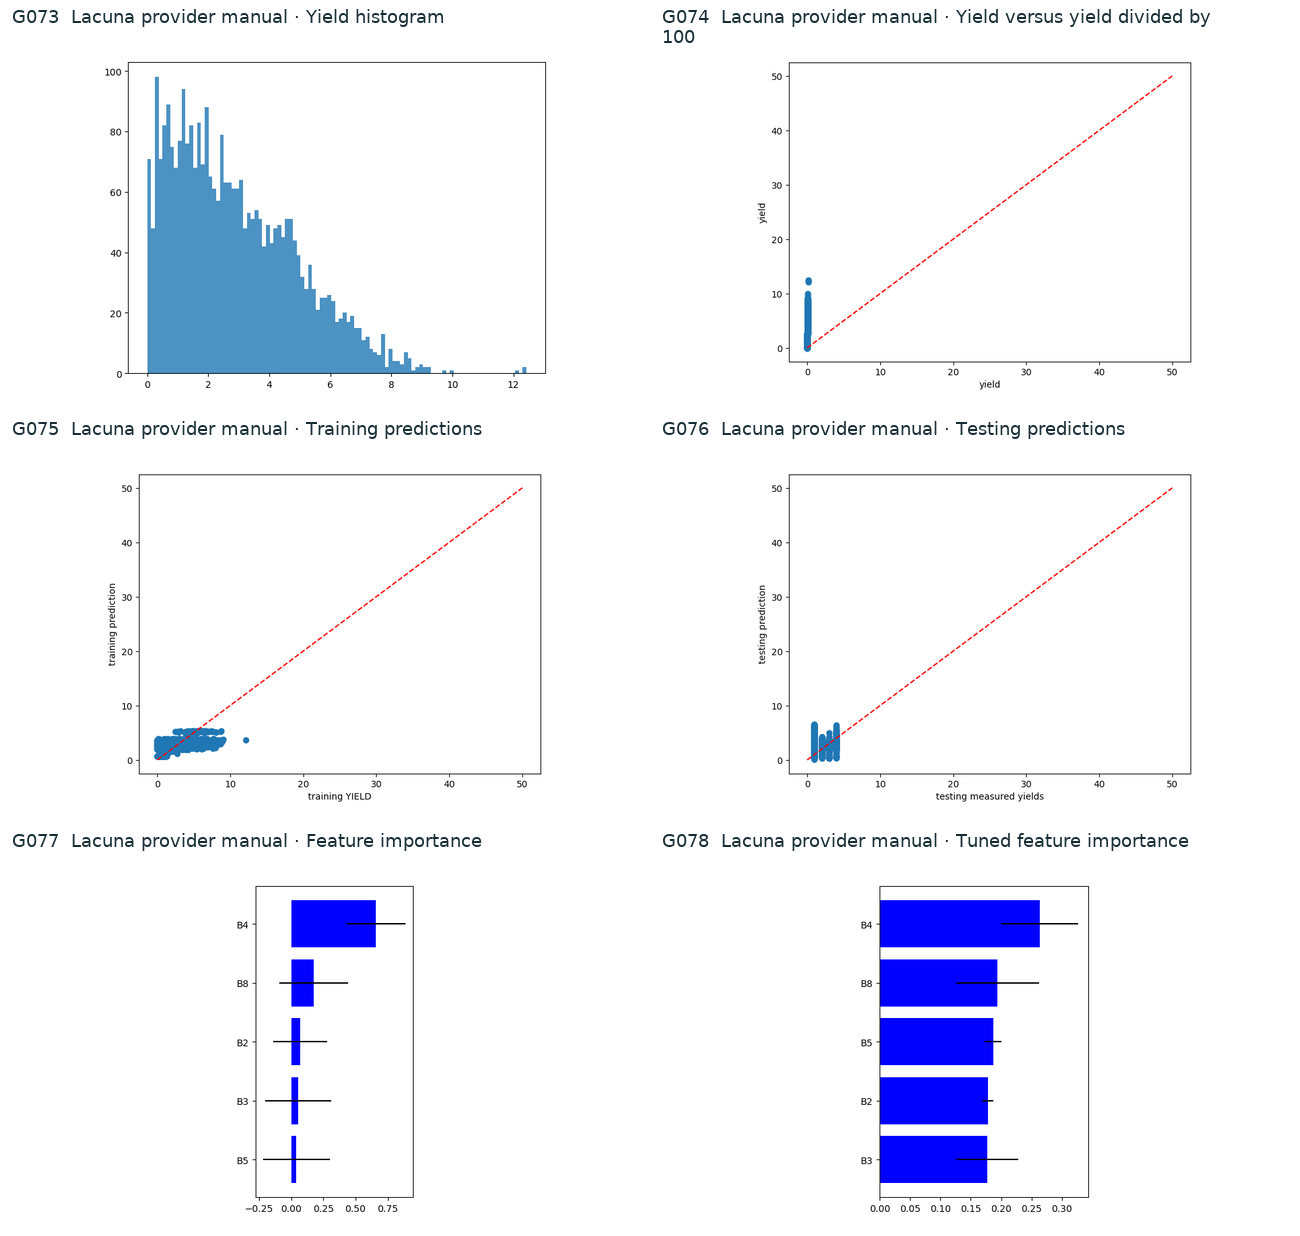

- **G073** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G074** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G075** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 6](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G076** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 4](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 7](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G077** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 5](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 8](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G078** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 6](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 9](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

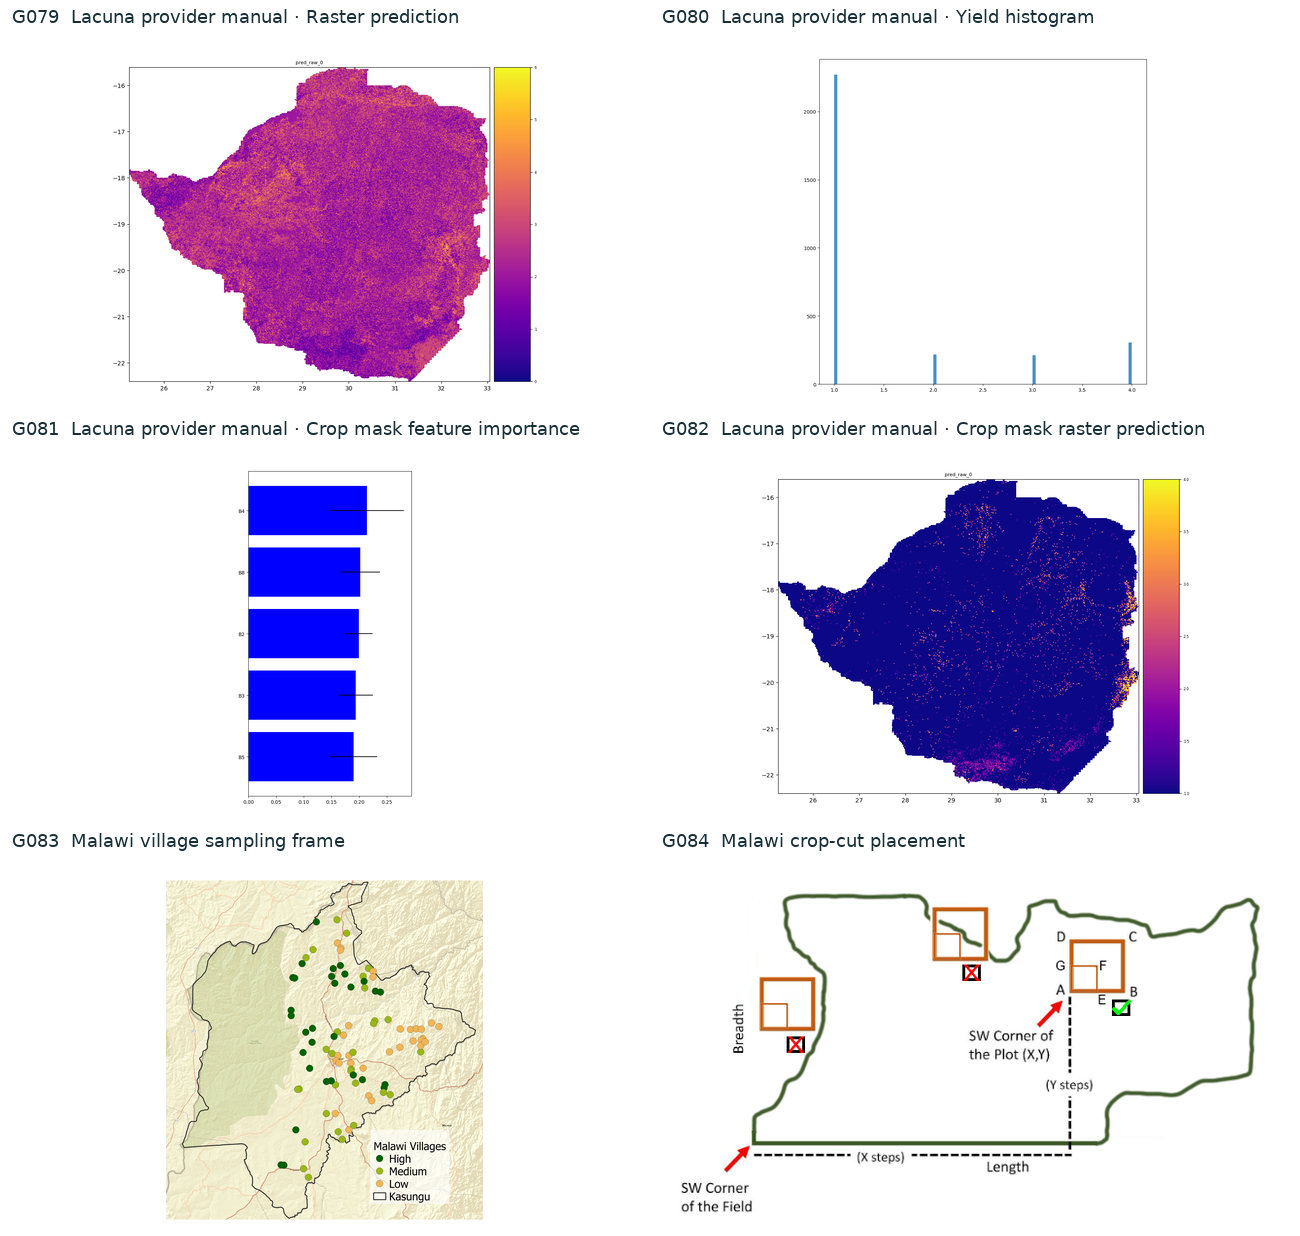

- **G079** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 7](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 11](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G080** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 8](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 12](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G081** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 9](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 15](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G082** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 10](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 16](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)
- **G083** [nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx · word/media/image1.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/malawi/nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx)
- **G084** [nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx · word/media/image2.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/malawi/nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx)

In [14]:
show_gallery(gallery, "Provider documentation figures")

### Reconstructed v2 report figures

4 unique previews · 4 figures referenced in this section.

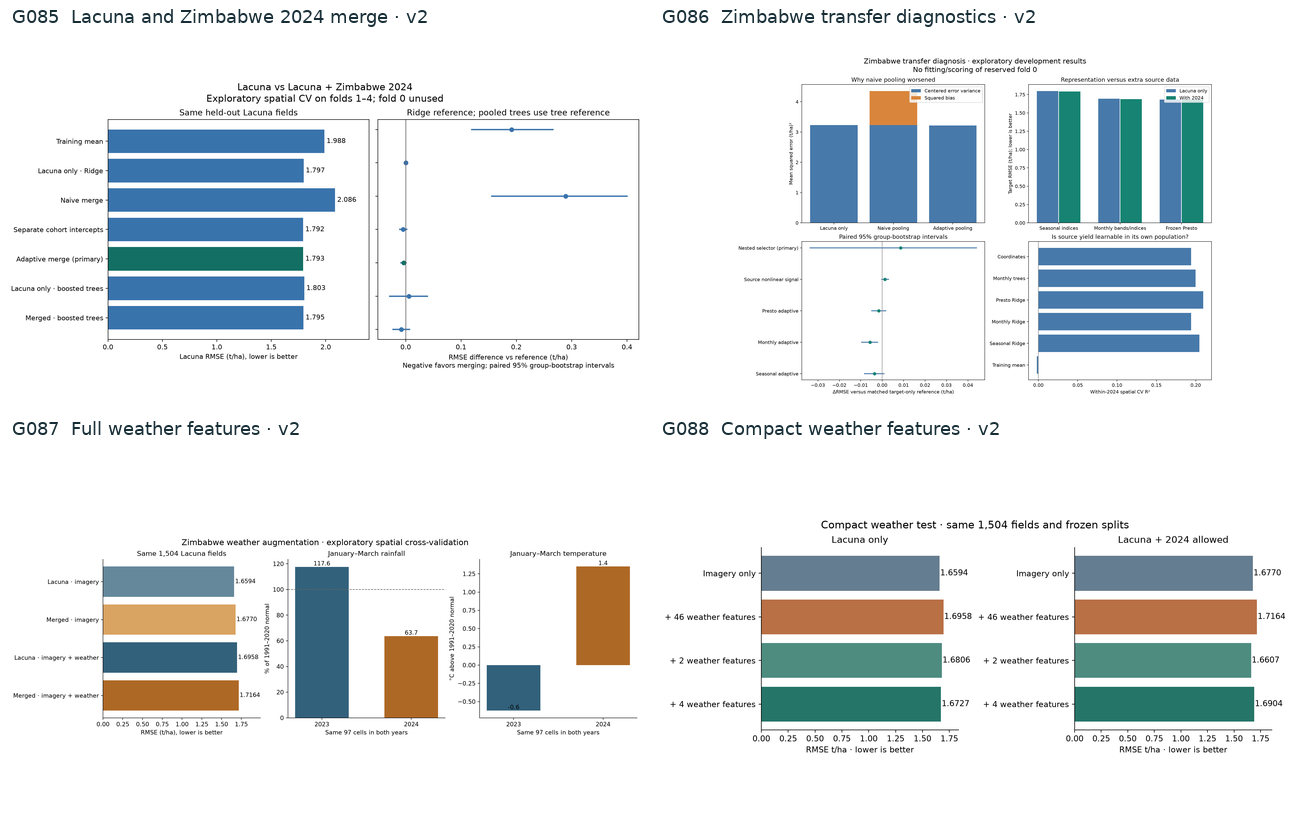

- **G085** [RESULTS.md · report link comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/merge_v2/merge/RESULTS.md)
- **G086** [RESULTS.md · report link diagnosis.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/merge_v2/diagnosis/RESULTS.md)
- **G087** [RESULTS.md · report link weather_comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/weather_v2/full/RESULTS.md)
- **G088** [RESULTS.md · report link compact_weather_comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/weather_v2/compact/RESULTS.md)

In [15]:
show_gallery(gallery, "Reconstructed v2 report figures")

### Reconstructed Presto diagnostics

18 unique previews · 18 figures referenced in this section.

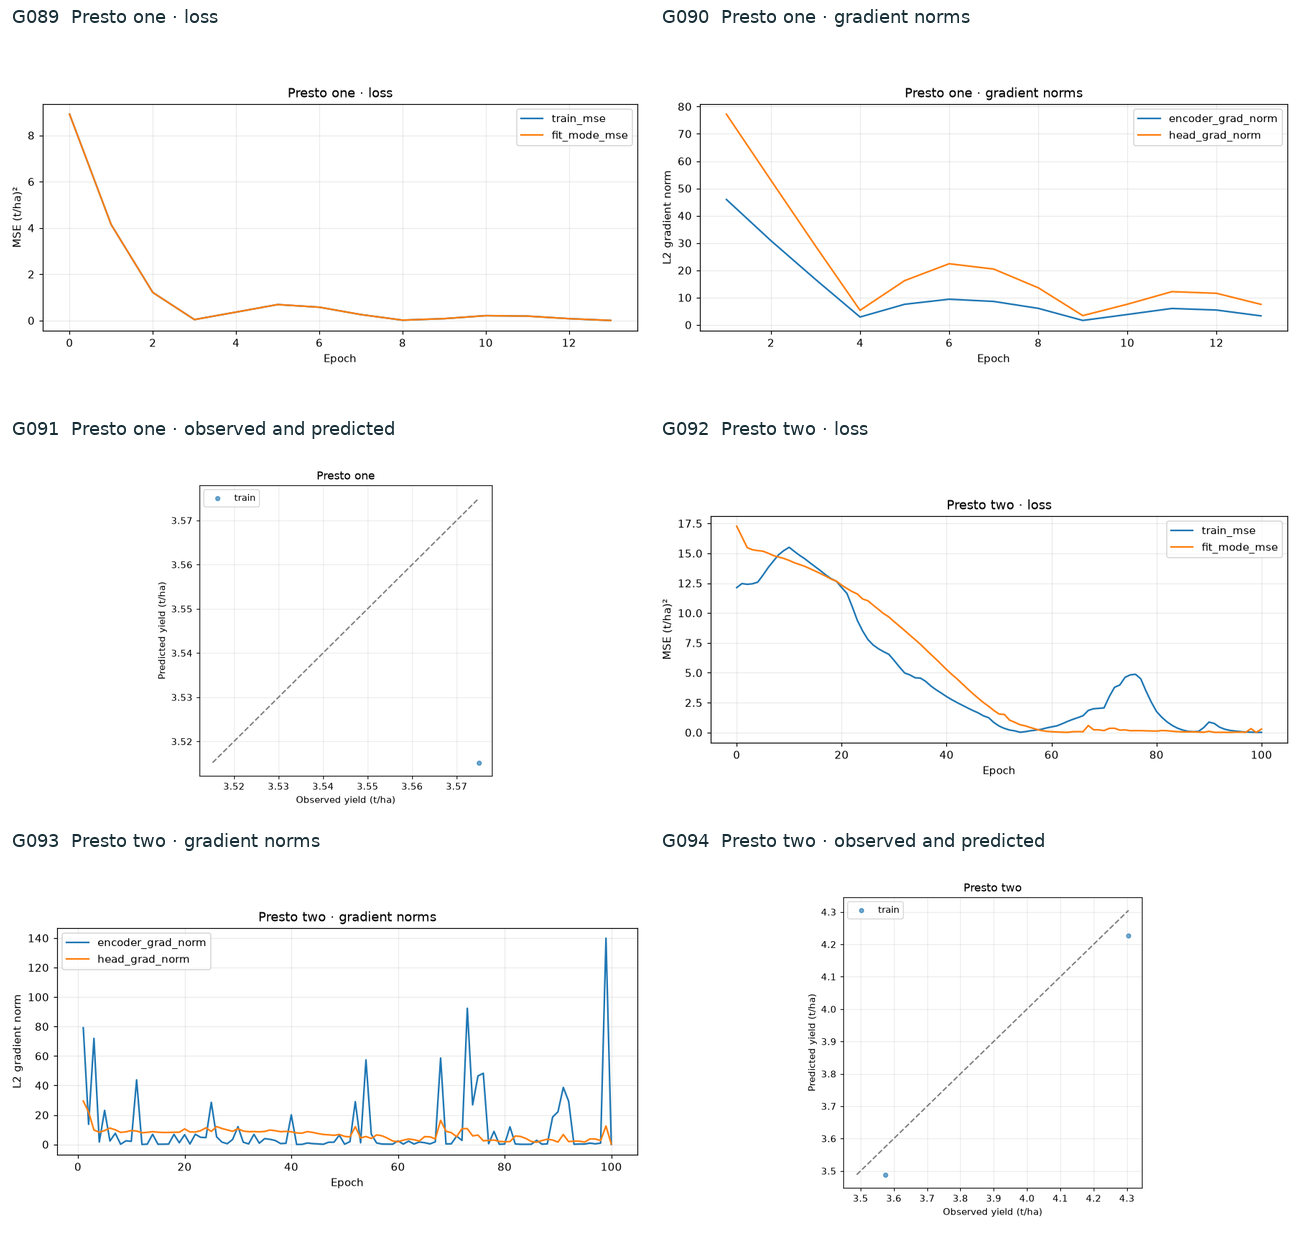

- **G089** [history.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/history.csv)
- **G090** [history.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/history.csv)
- **G091** [predictions.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/predictions.csv)
- **G092** [history.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/history.csv)
- **G093** [history.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/history.csv)
- **G094** [predictions.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/predictions.csv)

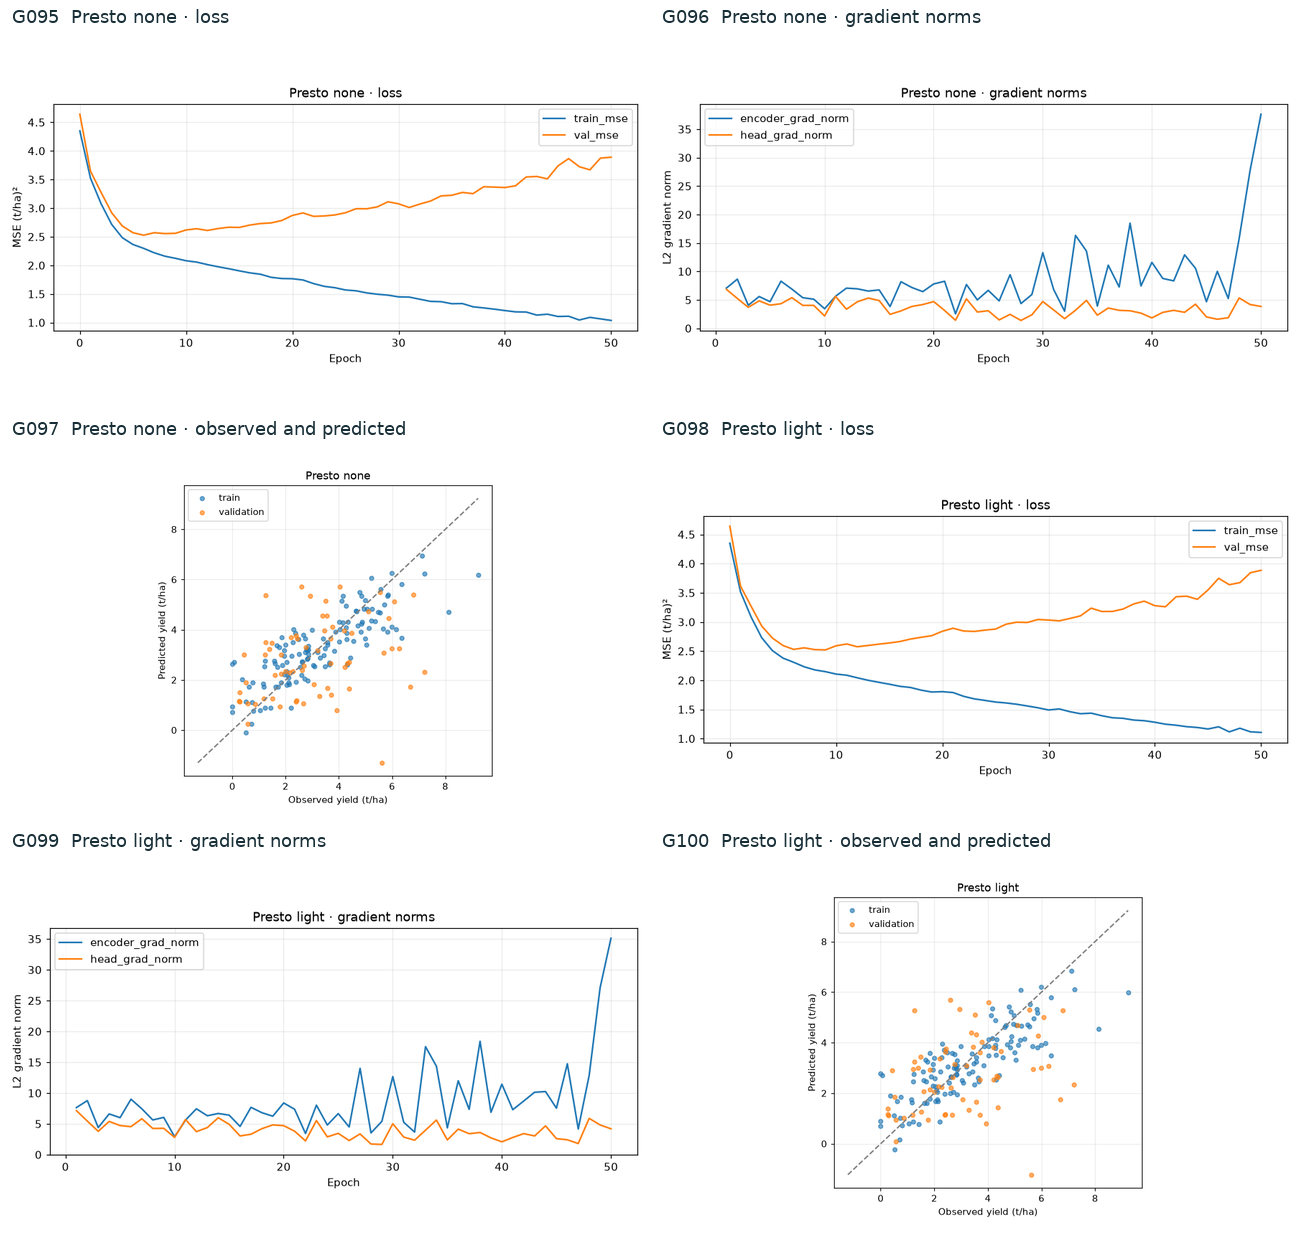

- **G095** [history.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/history.csv)
- **G096** [history.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/history.csv)
- **G097** [predictions.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/predictions.csv)
- **G098** [history.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/history.csv)
- **G099** [history.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/history.csv)
- **G100** [predictions.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/predictions.csv)

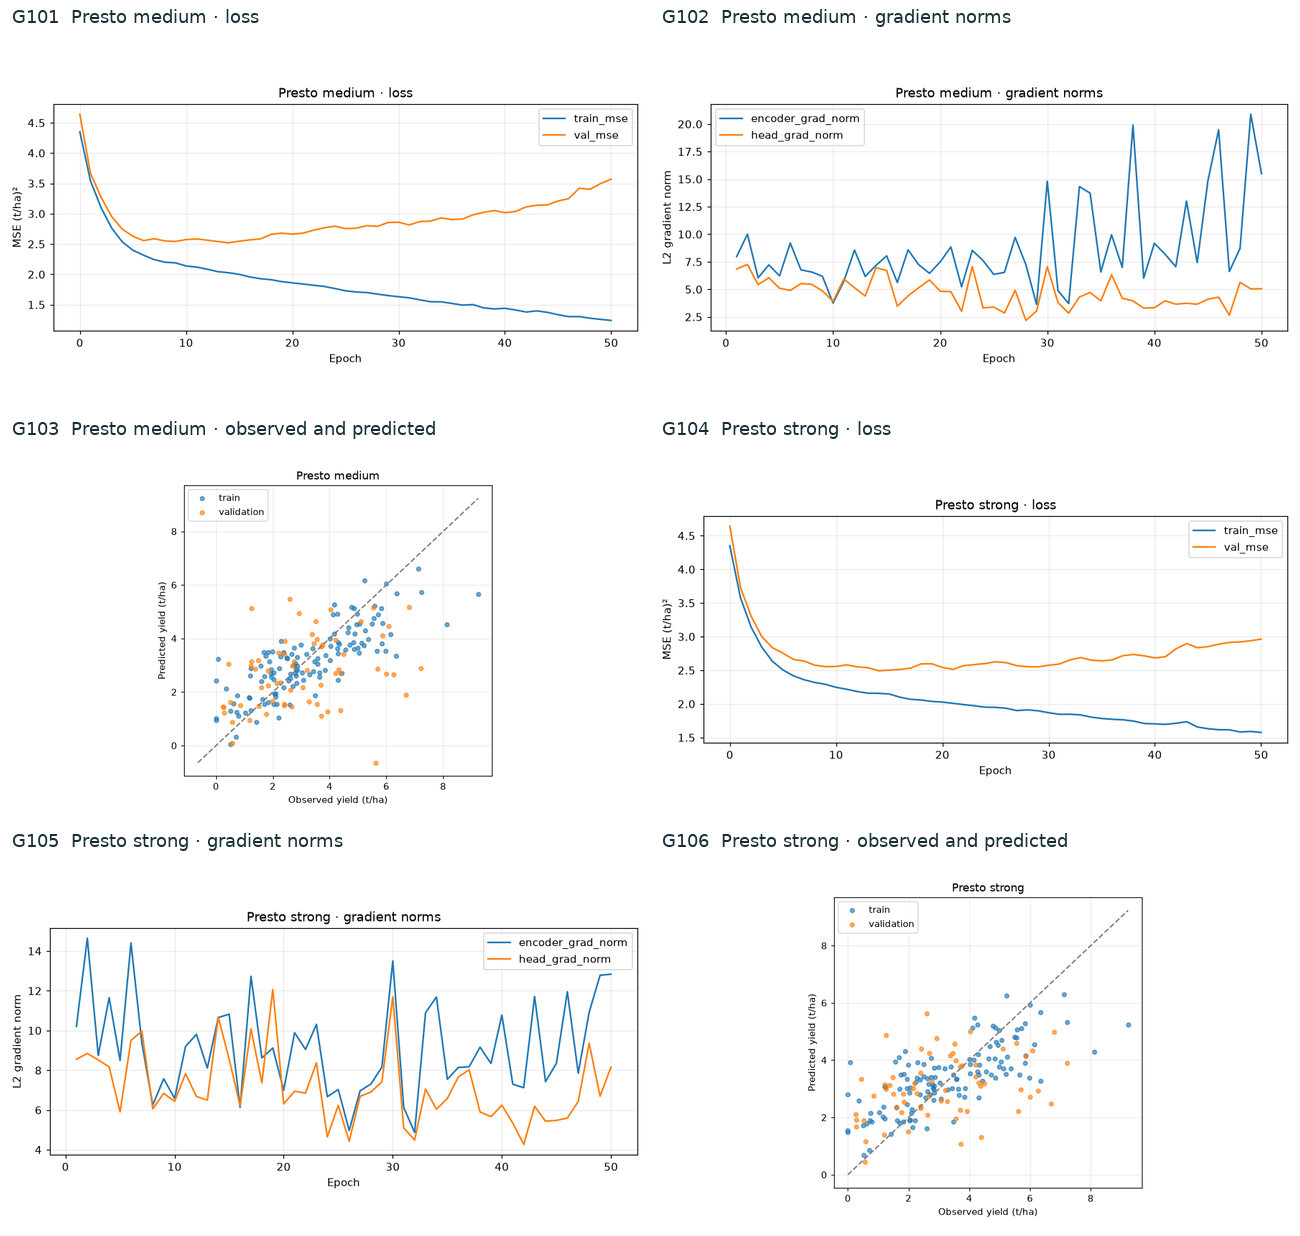

- **G101** [history.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/history.csv)
- **G102** [history.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/history.csv)
- **G103** [predictions.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/predictions.csv)
- **G104** [history.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/history.csv)
- **G105** [history.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/history.csv)
- **G106** [predictions.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/predictions.csv)

In [16]:
show_gallery(gallery, "Reconstructed Presto diagnostics")

In [17]:
# Enter an ID from the gallery to display its full-resolution image.
figure_id = ""
if figure_id:
    show_figure(gallery, figure_id.upper())